## Окружение

Создайте окружение `sc_pbmc` в терминале Linux (или терминале JupyterLab) и зарегистрируйте его как ядро Jupyter. `scikit-misc` необходим для отбора HVG методом `seurat_v3`.

```bash
mamba create -n sc_pbmc -c conda-forge python=3.11 scanpy scikit-misc jupyterlab ipykernel -y
mamba activate sc_pbmc
python -m ipykernel install --user --name sc_pbmc --display-name "sc_pbmc"
```

Выберите ядро **Python (sc_pbmc)**. Если `mamba` отсутствует, замените `mamba create` на `conda create`.

## Данные

**PBMC 3k** — клетки периферической крови здорового донора, секвенированные с помощью 10x Genomics (около 2700 клеток). Ниже скачивается исходная матрица UMI counts в формате Matrix Market, включая файлы генов и клеточных штрихкодов. После распаковки они окажутся в `data/filtered_gene_bc_matrices/hg19/`.

Источник: [10x Genomics — PBMC 3k](https://www.10xgenomics.com/datasets/3-k-pbm-cs-from-a-healthy-donor-1-standard-1-0-0) · [документация Scanpy](https://scanpy.readthedocs.io/en/latest/api/generated/scanpy.datasets.pbmc3k.html).

In [1]:
!mkdir -p data
!curl -fL https://cf.10xgenomics.com/samples/cell-exp/1.1.0/pbmc3k/pbmc3k_filtered_gene_bc_matrices.tar.gz -o data/pbmc3k.tar.gz
!tar -xzf data/pbmc3k.tar.gz -C data

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 7443k  100 7443k    0     0  41.2M      0 --:--:-- --:--:-- --:--:-- 41.3M


In [3]:
!pip install scanpy python-igraph leidenalg

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 44.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 88.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 74.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 190.2/190.2 kB 13.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 92.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.3/405.3 kB 31.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 16.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 61.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 5.6 MB/s eta 0:00:00
  Attempting uninstall: pandas
    Found existing instal

In [4]:
import scanpy as sc
import matplotlib.pyplot as plt
import numpy as np

In [5]:
adata = sc.read_10x_mtx("data/filtered_gene_bc_matrices/hg19/")

In [6]:
adata

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'
    layers: None (.X)

In [7]:
adata.var

,gene_ids
MIR1302-10,ENSG00000243485
FAM138A,ENSG00000237613
OR4F5,ENSG00000186092
RP11-34P13.7,ENSG00000238009
RP11-34P13.8,ENSG00000239945
...,...
AC145205.1,ENSG00000215635
BAGE5,ENSG00000268590
CU459201.1,ENSG00000251180
AC002321.2,ENSG00000215616


In [8]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")

In [9]:
adata.var

,gene_ids,mt
MIR1302-10,ENSG00000243485,False
FAM138A,ENSG00000237613,False
OR4F5,ENSG00000186092,False
RP11-34P13.7,ENSG00000238009,False
RP11-34P13.8,ENSG00000239945,False
...,...,...
AC145205.1,ENSG00000215635,False
BAGE5,ENSG00000268590,False
CU459201.1,ENSG00000251180,False
AC002321.2,ENSG00000215616,False


In [10]:
adata.var_names[adata.var["mt"]]

Index(['MT-ND1', 'MT-ND2', 'MT-CO1', 'MT-CO2', 'MT-ATP8', 'MT-ATP6', 'MT-CO3',
       'MT-ND3', 'MT-ND4L', 'MT-ND4', 'MT-ND5', 'MT-ND6', 'MT-CYB'],
      dtype='str')

# Какие есть ещё поля в AnnData?

## Структура AnnData

Основная матрица имеет размер:

$$
\underbrace{C}_{\text{клетки}}
\times
\underbrace{G}_{\text{гены}}
$$

- **Строки** — клетки (observations).
- **Столбцы** — гены (variables).
- **Элементы** — значения экспрессии генов в клетках.

Здесь `adata.X` — название поля AnnData, а не матрица отдельных UMI $X_{ig}$ из нашей вероятностной модели. В `adata.X` мы обычно храним матрицу $Y_{ci}$.

### Основные поля AnnData

| Поле | Размерность | Что хранит |
|---|---|---|
| `adata.X` | $C\times G$ | Основная матрица экспрессии |
| `adata.obs` | $C\times K$ | Таблица характеристик клеток |
| `adata.var` | $G\times L$ | Таблица характеристик генов |
| `adata.obs_names` | $C$ | Идентификаторы клеток (индекс `obs`) |
| `adata.var_names` | $G$ | Идентификаторы генов (индекс `var`) |
| `adata.layers` | Каждая матрица $C\times G$ | Дополнительные версии матрицы экспрессии |
| `adata.obsm` | $C\times d$ | Многомерные представления клеток |
| `adata.varm` | $G\times d$ | Многомерные представления генов |
| `adata.obsp` | $C\times C$ | Матрицы отношений между клетками |
| `adata.varp` | $G\times G$ | Матрицы отношений между генами |
| `adata.uns` | Произвольная | Параметры, словари и другие результаты анализа |
| `adata.raw` | Снимок $C\times G_{\mathrm{raw}}$ | Сохранённые `X`, `var` и имена генов |

Здесь $K$ и $L$ — количества столбцов с метаданными, а $d$ — число измерений в многомерном представлении.

In [11]:
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, inplace=True)

In [12]:
 adata

AnnData object with n_obs × n_vars = 2700 × 32738
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    layers: None (.X)

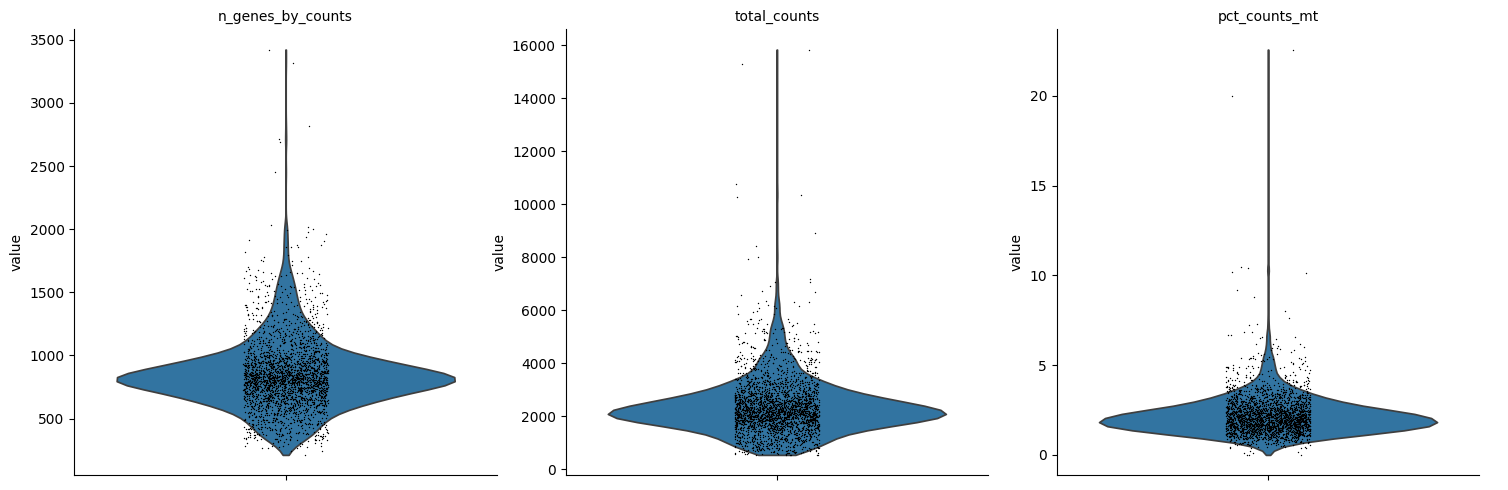

In [13]:
sc.pl.violin(adata, ["n_genes_by_counts", "total_counts", "pct_counts_mt"], multi_panel=True)

In [14]:
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)

In [15]:
adata = adata[(adata.obs.n_genes_by_counts < 2500) & (adata.obs.pct_counts_mt < 5)].copy()

In [16]:
adata.layers["counts"] = adata.X.copy()

In [17]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    layers: None (.X), 'counts'

In [20]:
!pip install scikit-misc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.4/183.4 kB 6.7 MB/s eta 0:00:00


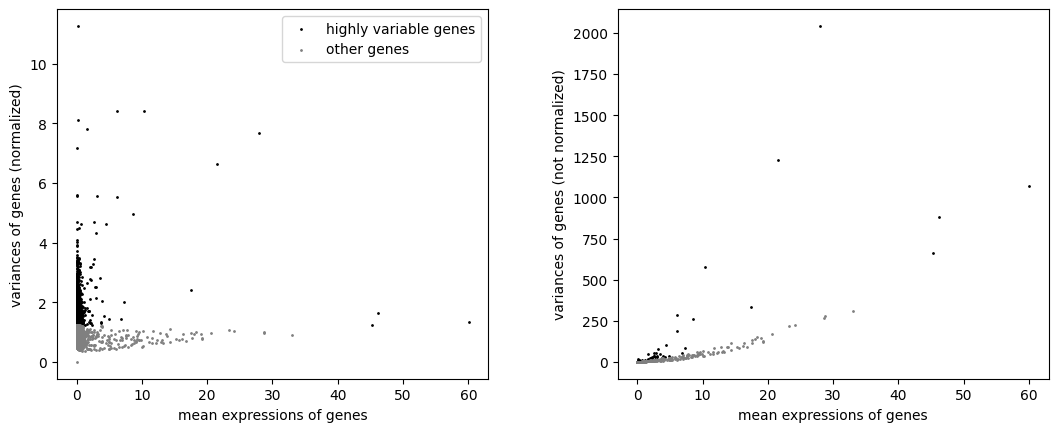

In [21]:
sc.pp.highly_variable_genes(adata, layer="counts", flavor="seurat_v3", n_top_genes=2000)
sc.pl.highly_variable_genes(adata)

In [22]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg'
    layers: None (.X), 'counts'

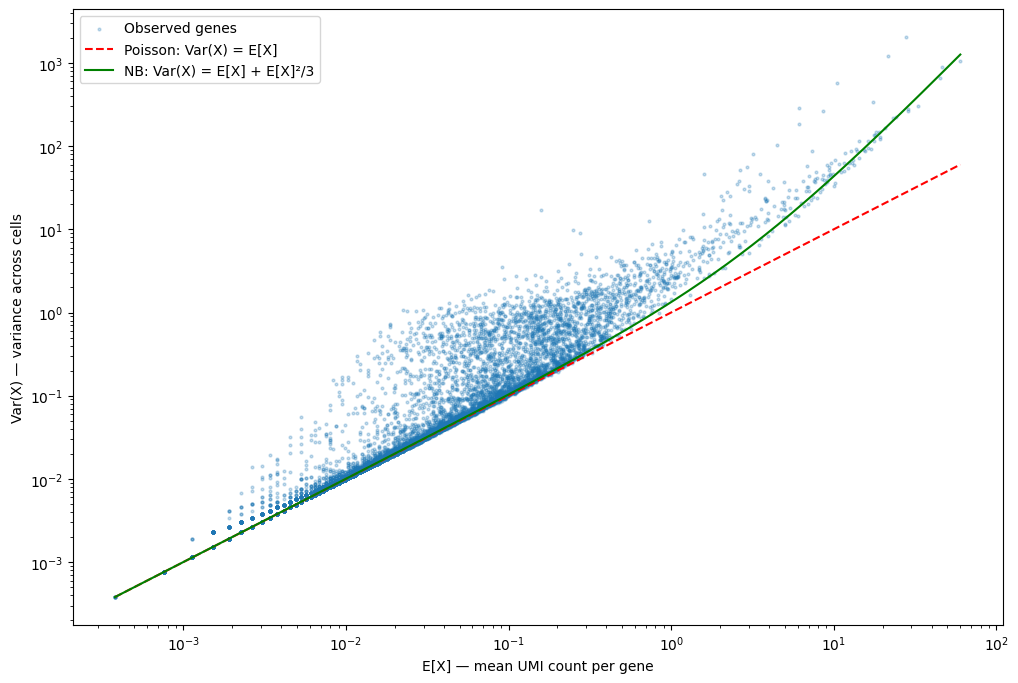

In [23]:
plt.figure(figsize=(12, 8))

mean = adata.var["means"].to_numpy()
var = adata.var["variances"].to_numpy()
valid = (mean > 0) & (var > 0)

theta = 3

x = np.geomspace(mean[valid].min(), mean[valid].max(), 200)

plt.scatter(mean[valid], var[valid], s=4, alpha=0.25, label="Observed genes")

plt.plot(x, x, "r--", label="Poisson: Var(X) = E[X]")
plt.plot(x, x + x**2/theta, "g-", label=f"NB: Var(X) = E[X] + E[X]²/{theta}")

plt.xscale("log")
plt.yscale("log")
plt.xlabel("E[X] — mean UMI count per gene")
plt.ylabel("Var(X) — variance across cells")
plt.legend()
plt.show()

In [24]:
sc.pp.normalize_total(adata, target_sum=1e4) # учитываем разный размер библиотеки. Нормализуем на глубину секвенирования
sc.pp.log1p(adata) # уменьшаем влияние сильно экспрессируемых генов

In [25]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p'
    layers: None (.X), 'counts'

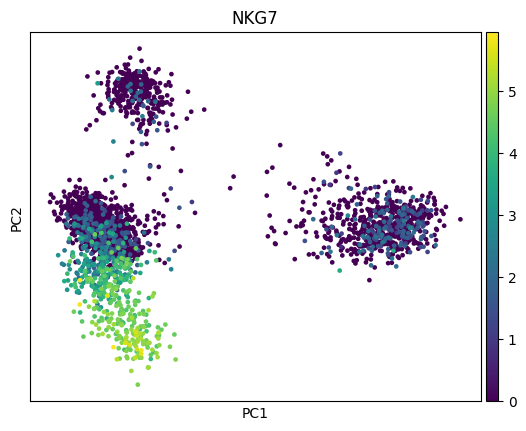

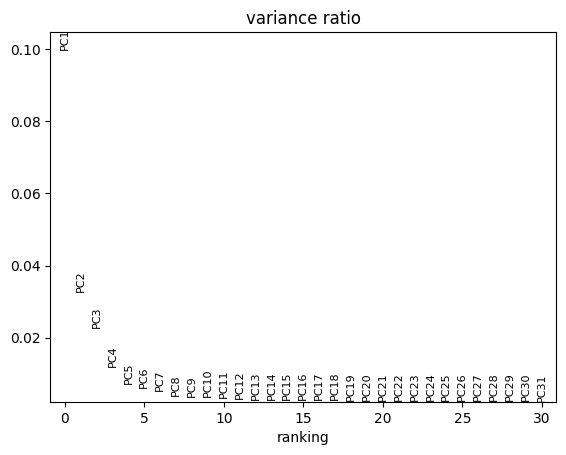

In [26]:
sc.tl.pca(adata, mask_var="highly_variable")
sc.pl.pca(adata, color="NKG7")
sc.pl.pca_variance_ratio(adata)

In [27]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: None (.X), 'counts'

## Подумайте

* Посмотрите что сейчас находится в слоях anndata. Что из себя представляют новые слои?
* По каким генам можно ещё делать QC?   
* Как лучше делать QC: по поиску генов по названиям в матрице или с помощью gtf/gff файла?
* Сколько есть генов на митохондриальной хросоме? Все ли они начинаются с mt?
* У человека митохондриальные гены начинаются с MT, у мыши с mt. Как начинаются митохондриальные гены у других организмов: у коров, собак, приматов?

**Во всех заданиях если не сказано иного используйте анализ с использованием филтрации по QC и PCA с использованием HVG**

1. В `adata` лежит два представления одной и той же матрицы:
`adata.X` - нормированные на 10 000 UMI и логарифмированные значения, `adata.layers["counts"]` - сырые UMI, снятые до нормализации. Копия сырых counts нужна потому, что `seurat_v3` и
pearson residuals работают только с целочисленными counts, а большинство остальных методов — с лог-нормированной матрицей. Плюс появились `obsm["X_pca"]`, `varm["PCs"]` и записи в `uns`
(`hvg`, `log1p`, `pca`) — это уже результаты анализа, а не версии матрицы экспрессии.

2. Практически полезны:
рибосомные белки (`RPS*`, `RPL*`) — высокая доля характерна для мелких клеток с низкой сложностью библиотеки, но также и для нормальных активно трансляционных клеток;
гемоглобины (`HBB`, `HBA1/2`, `HBD`, ...) — остаточные эритроциты и свободный гемоглобин, налипший на клетки, особенно актуально для крови;
`MALAT1` - ядерная lncRNA; очень высокая доля при почти отсутствующей цитоплазматической фракции указывает на «голые ядра»;
гены теплового шока (`HSPA*`, `HSPB*`, `DNAJ*`) — стресс диссоциации;
доля UMI в топ-20/50 генах (`percent_top`) — интегральная мера сложности библиотеки;
для других тканей — гены клеточного цикла, маркеры тромбоцитов (`PPBP`, `PF4`) и т.д.

3. Поиск по префиксу имени - быстро, но сломается, так как имена генов меняются между релизами аннотации, ядерные гомологи и псевдогены ловятся
по тому же префиксу (`MTRNR2L1`, `MTHFR`, `MTOR` — все «на MT»), а в чужих сборках префикса может не быть вовсе. Правильный способ - взять из GTF/GFF координаты и отобрать гены по имени хромосомы (`chrM`/`MT`), то есть по биологическому признаку, а не по строке. На практике так и делают, когда
аннотация под рукой; префикс оставляют для быстрой разведки.

4. В митохондриальном геноме человека 37 генов: 13 кодирующих белки,
22 тРНК и 2 рРНК. В стандартной 10x-референсной аннотации hg19 в матрице остаются только 13 белок-кодирующих генов (MT-ND1…MT-CYB), а рРНК (MT-RNR1, MT-RNR2) и тРНК отфильтрованы. Все настоящие митохондриальные гены начинаются с `MT-`, но обратное неверно: `MTRNR2L8`, `MTHFD1`, `MTOR` — ядерные. Отдельная ловушка — ядерные
гены митохондриальных рибосом `MRPL*`/`MRPS*`: они кодируются в ядре и к митохондриальной доле UMI отношения не имеют.

5. Единого правила нет, префикс определяется источником аннотации. В Ensembl у мыши это `mt-Nd1` (общая для мыши конвенция «первая буква заглавная»), у человека и ряда приматов — `MT-ND1`, у коровы и собаки в Ensembl тоже встречается форма `MT-ND1`, но в сборках NCBI те же гены могут называться просто `ND1`, `COX1`, `CYTB` — без префикса. Поэтому для любого
не-модельного организма правило «startswith» нужно сначала проверить глазами на `adata.var_names`, а надёжнее — отбирать по хромосоме из GTF.

In [28]:
print("слои:", list(adata.layers))
print("obsm:", list(adata.obsm))
print("varm:", list(adata.varm))
print("uns:", list(adata.uns))

print("\nadata.X после normalize_total + log1p, максимум:", adata.X.max())
print("adata.layers['counts'] — сырые UMI, максимум:", adata.layers["counts"].max())

слои: [None, 'counts']
obsm: ['X_pca']
varm: ['PCs']
uns: ['hvg', 'log1p', 'pca']

adata.X после normalize_total + log1p, максимум: 7.4695992
adata.layers['counts'] — сырые UMI, максимум: 419.0


In [29]:
mt_genes = adata.var_names[adata.var["mt"]]
print("митохондриальных генов в матрице после фильтрации:", len(mt_genes))
print(list(mt_genes))

# «MT» без дефиса ловит ядерные псевдогены MTRNR2L* и всю группу MTOR/MTHFR
print("\nначинаются на MT (без дефиса):", sum(adata.var_names.str.startswith("MT")))
print("ядерные гены митохондриальных рибосом MRPL/MRPS:",
      sum(adata.var_names.str.startswith(("MRPL", "MRPS"))))

митохондриальных генов в матрице после фильтрации: 13
['MT-ND1', 'MT-ND2', 'MT-CO1', 'MT-CO2', 'MT-ATP8', 'MT-ATP6', 'MT-CO3', 'MT-ND3', 'MT-ND4L', 'MT-ND4', 'MT-ND5', 'MT-ND6', 'MT-CYB']

начинаются на MT (без дефиса): 77
ядерные гены митохондриальных рибосом MRPL/MRPS: 76


## Задание 1
Сделайте QC по предложенным вами генам/группам генов и постройти графики для всех QC - и тех что мы сделали сами и тех что вы предложили.

Для каждой группы генов/гена рассчитайте долю UMI от общего количества UMI клетки.

Постройте для всех QC-метрик (включая рассчитанные на занятии):

1. Violin plot.
2. Гистограмму распределения:
   - X — значение QC-метрики;
   - Y — количество клеток.
3. Scatter plot зависимости количества обнаруженных генов от общего количества UMI.

**Вопросы:** Какие клетки выглядят подозрительными? Какие метрики могут свидетельствовать о низком качестве клетки? Почему высокая доля определённой группы генов не всегда означает плохое качество?


In [30]:
import re
from itertools import combinations

import pandas as pd

RAW_PATH = "data/filtered_gene_bc_matrices/hg19/"

GENE_GROUPS = {
    "mt": lambda g: g.str.startswith("MT-"),
    "ribo": lambda g: g.str.startswith(("RPS", "RPL")),
    "hb": lambda g: g.str.match(r"^HB[ABDEGMQZ]\d?$"),
    "hsp": lambda g: g.str.startswith(("HSPA", "HSPB", "HSPD", "HSPE", "HSPH", "DNAJ")),
    "malat1": lambda g: g == "MALAT1",
}

QC_COLS = ["n_genes_by_counts", "total_counts"] + [f"pct_counts_{k}" for k in GENE_GROUPS]
MARKERS = ["CD3D", "MS4A1", "NKG7", "LST1"]


def load_raw():
    a = sc.read_10x_mtx(RAW_PATH)
    a.var_names_make_unique()
    for name, rule in GENE_GROUPS.items():
        a.var[name] = np.asarray(rule(a.var_names), dtype=bool)
    sc.pp.calculate_qc_metrics(a, qc_vars=list(GENE_GROUPS), percent_top=None, inplace=True)
    return a


def preprocess(qc=True, hvg=True, normalize=True, log=True, n_top_genes=2000):
    a = load_raw()
    if qc:
        sc.pp.filter_cells(a, min_genes=200)
        sc.pp.filter_genes(a, min_cells=3)
        a = a[(a.obs.n_genes_by_counts < 2500) & (a.obs.pct_counts_mt < 5)].copy()
    else:
        sc.pp.filter_genes(a, min_cells=1)

    a.layers["counts"] = a.X.copy()

    if hvg:
        sc.pp.highly_variable_genes(a, layer="counts", flavor="seurat_v3", n_top_genes=n_top_genes)
    if normalize:
        sc.pp.normalize_total(a, target_sum=1e4)
    if log:
        sc.pp.log1p(a)
    return a


def gene_means_and_vars(matrix):
    """Среднее и дисперсия по столбцам разреженной матрицы, без приведения к плотной."""
    mean = np.asarray(matrix.mean(axis=0)).ravel()
    squared = matrix.copy()
    squared.data = squared.data ** 2
    mean_sq = np.asarray(squared.mean(axis=0)).ravel()
    return mean, mean_sq - mean ** 2

In [31]:
raw = load_raw()

sizes = {name: int(raw.var[name].sum()) for name in GENE_GROUPS}
print("клеток:", raw.n_obs, "| генов:", raw.n_vars)
print("генов в группах:", sizes)
raw.obs[QC_COLS].describe().T.round(2)

клеток: 2700 | генов: 32738
генов в группах: {'mt': 13, 'ribo': 106, 'hb': 10, 'hsp': 78, 'malat1': 1}


,count,mean,std,min,25%,50%,75%,max
n_genes_by_counts,2700.0,846.99,282.10,212.00,690.00,817.00,953.25,3422.00
total_counts,2700.0,2366.90,1094.26,548.00,1757.75,2197.00,2763.00,15844.00
pct_counts_mt,2700.0,2.22,1.17,0.00,1.54,2.03,2.64,22.57
pct_counts_ribo,2700.0,34.95,10.22,1.06,26.33,36.77,43.35,59.44
pct_counts_hb,2700.0,0.00,0.03,0.00,0.00,0.00,0.00,1.36
pct_counts_hsp,2700.0,0.27,0.24,0.00,0.16,0.24,0.34,7.58
pct_counts_malat1,2700.0,2.81,1.80,0.00,1.56,2.59,3.64,17.51


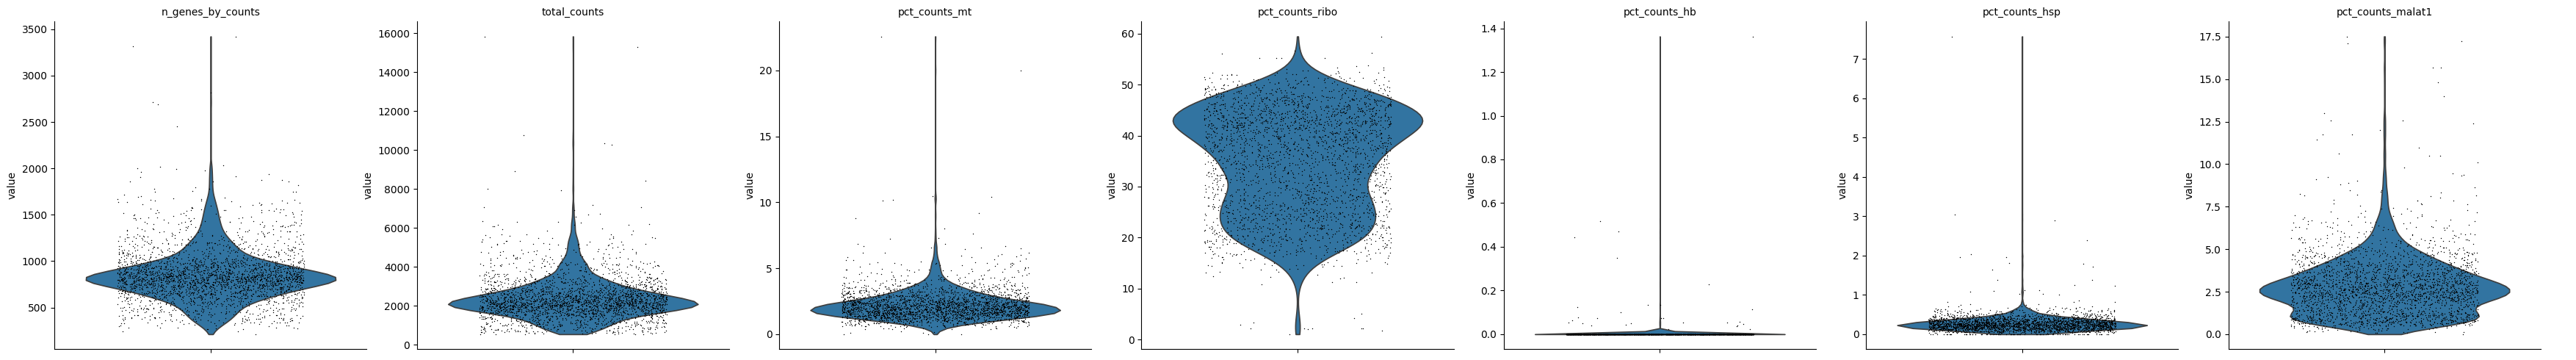

In [32]:
sc.pl.violin(raw, QC_COLS, multi_panel=True, jitter=0.3)

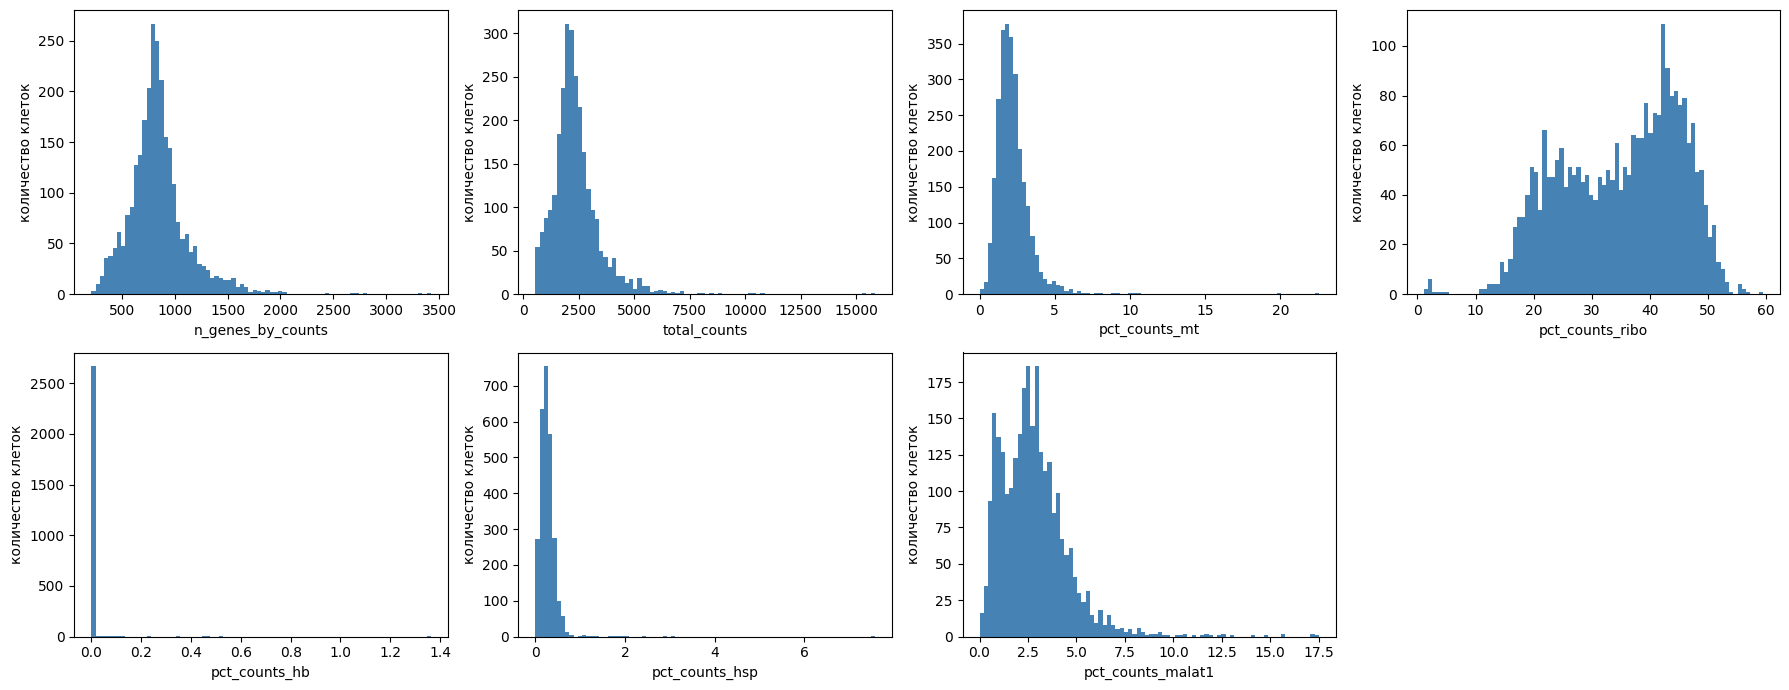

In [33]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))

for ax, col in zip(axes.flat, QC_COLS):
    ax.hist(raw.obs[col], bins=80, color="steelblue")
    ax.set_xlabel(col)
    ax.set_ylabel("количество клеток")

axes.flat[-1].axis("off")
fig.tight_layout()
plt.show()

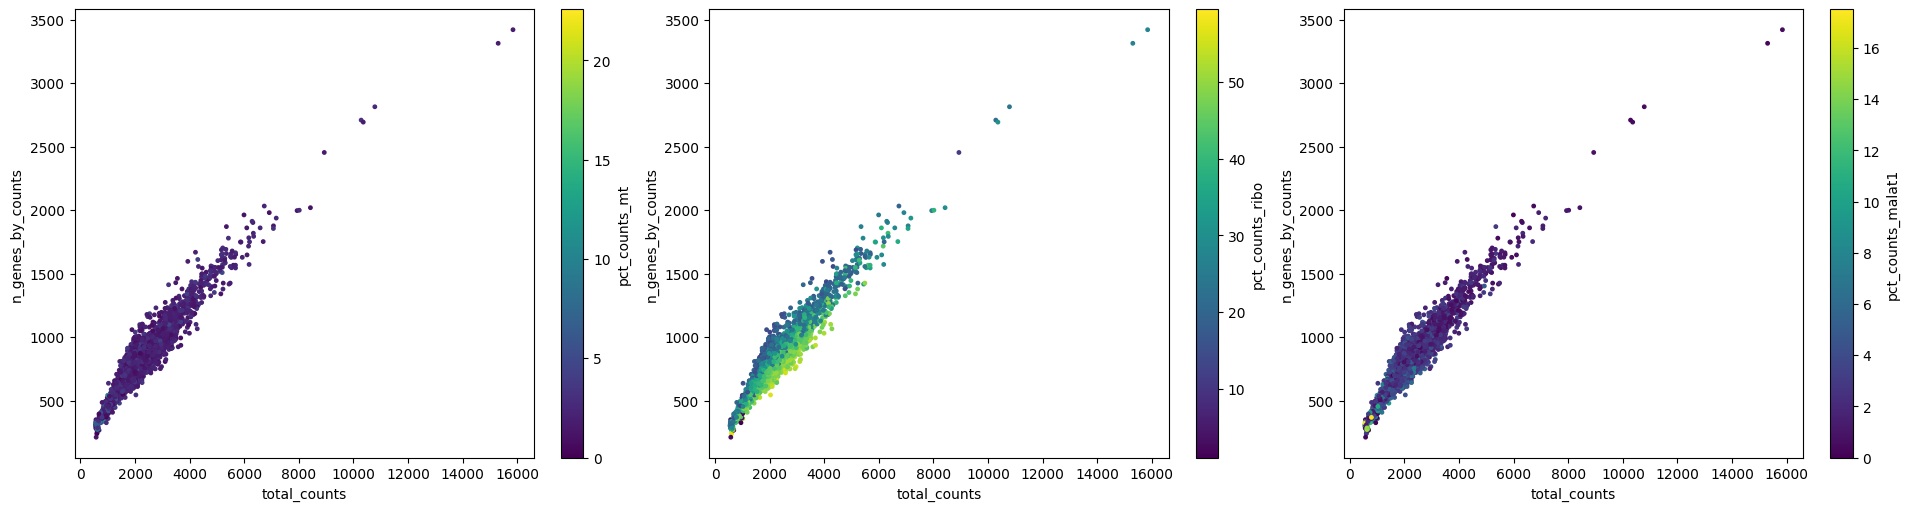

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5), constrained_layout=True)

for ax, color in zip(axes, ["pct_counts_mt", "pct_counts_ribo", "pct_counts_malat1"]):
    sp = ax.scatter(raw.obs.total_counts, raw.obs.n_genes_by_counts,
                    c=raw.obs[color], s=6, cmap="viridis")
    ax.set_xlabel("total_counts")
    ax.set_ylabel("n_genes_by_counts")
    fig.colorbar(sp, ax=ax, label=color)

plt.show()

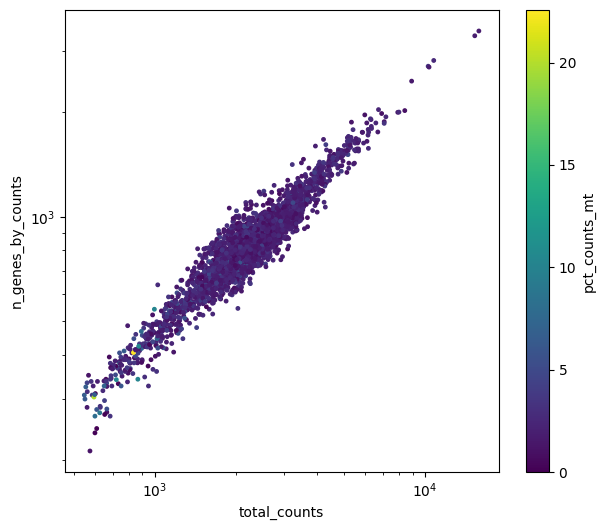

In [36]:
# то же самое в логарифмических осях: при большом разбросе глубины так лучше видно плохие клетки
fig, ax = plt.subplots(figsize=(7, 6))
sp = ax.scatter(raw.obs.total_counts, raw.obs.n_genes_by_counts,
                c=raw.obs.pct_counts_mt, s=6, cmap="viridis")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("total_counts")
ax.set_ylabel("n_genes_by_counts")
fig.colorbar(sp, label="pct_counts_mt")
plt.show()

In [35]:
flags = pd.DataFrame({
    "мало генов (<200)": raw.obs.n_genes_by_counts < 200,
    "много генов (>2500)": raw.obs.n_genes_by_counts > 2500,
    "mt > 5%": raw.obs.pct_counts_mt > 5,
    "ribo > 50%": raw.obs.pct_counts_ribo > 50,
    "hb > 1%": raw.obs.pct_counts_hb > 1,
    "malat1 > 10%": raw.obs.pct_counts_malat1 > 10,
})

summary = flags.sum().to_frame("клеток")
summary["доля, %"] = (100 * flags.mean()).round(2)
print("хотя бы один флаг:", int(flags.any(axis=1).sum()), "из", raw.n_obs)
summary

хотя бы один флаг: 162 из 2700


,клеток,"доля, %"
мало генов (<200),0,0.00
много генов (>2500),5,0.19
mt > 5%,57,2.11
ribo > 50%,87,3.22
hb > 1%,1,0.04
malat1 > 10%,20,0.74


1. Матрица 10x уже отфильтрована по вызову клеток, так что плохого мало: минимум 212 генов - порог min_genes=200 почти ничего не режет. Хвосты: число генов от медианы 817 до 3422 (кандидаты в дублеты, оторвавшиеся точки справа вверху на scatter'е); pct_counts_mt при медиане 2.03% доходит до 22.57% — повреждённые клетки; MALAT1 (один ген, 2.81% в среднем, до 17.51%) на верхних значениях — ядра. Гемоглобинов почти нет (максимум 1.36%), эритроцитарной примеси в препарате нет.

2. Метрики низкого качества. Высокая мт-доля (мембрана порвана, цитоплазматическая мРНК вытекла, митохондриальная осталась); низкие total_counts и n_genes_by_counts одновременно; высокая доля MALAT1 при низкой сложности; гемоглобины в крови. Ни одна не работает в одиночку: мало UMI может просто означать мелкую клетку — лимфоцит против моноцита.

3. 106 рибосомных генов из 32738 дают 34.95% всех UMI, у отдельных клеток до 59%. Если бы это был признак брака, пришлось бы выкинуть половину датасета. Гистограмма pct_counts_ribo бимодальная (горбы около 22% и 43%) — это два типа клеток: у мелких лимфоцитов доля трансляционного аппарата выше, у моноцитов её разбавляют собственные транскрипты (LYZ, S100A8/A9). Фактически эта метрика здесь работает как маркер типа — в задании 2 та же ось разделит клетки на PC1.

## Задание 2. Сравнение методов отбора HVG

Мы использовали `seurat_v3`. Повторите отбор HVG методом `seurat`, а также попробуйте использовать `sc.experimental.pp.highly_variable_genes`.

Постройте PCA на генах, отобранных каждым методом. Для обоих PCA используйте одинаковую нормализованную и логарифмированную матрицу экспрессии.

Окрасьте клетки по экспрессии известных маркеров иммунных популяций:

| Популяция | Ген |
|---|---|
| T-клетки | `CD3D` |
| B-клетки | `MS4A1` |
| NK-клетки | `NKG7` |
| Моноциты | `LST1` |

Эти гены используются как ориентиры, а не как окончательные аннотации клеточных типов.

**Вопросы:** Насколько отличаются расположения клеток? Сохраняются ли группы клеток с характерной экспрессией маркеров? Сколько генов одновременно попало в оба набора HVG?


In [38]:
base = preprocess(hvg=False)
hvg_sets = {}

v3 = base.copy()
sc.pp.highly_variable_genes(v3, layer="counts", flavor="seurat_v3", n_top_genes=2000)
hvg_sets["seurat_v3"] = v3.var_names[v3.var.highly_variable]

seurat = base.copy()
sc.pp.highly_variable_genes(seurat, flavor="seurat", n_top_genes=2000)
hvg_sets["seurat"] = seurat.var_names[seurat.var.highly_variable]

pearson = base.copy()
sc.experimental.pp.highly_variable_genes(
    pearson, flavor="pearson_residuals", layer="counts", n_top_genes=2000
)
hvg_sets["pearson_residuals"] = pearson.var_names[pearson.var.highly_variable]

{k: len(v) for k, v in hvg_sets.items()}

{'seurat_v3': 2000, 'seurat': 2000, 'pearson_residuals': 2000}

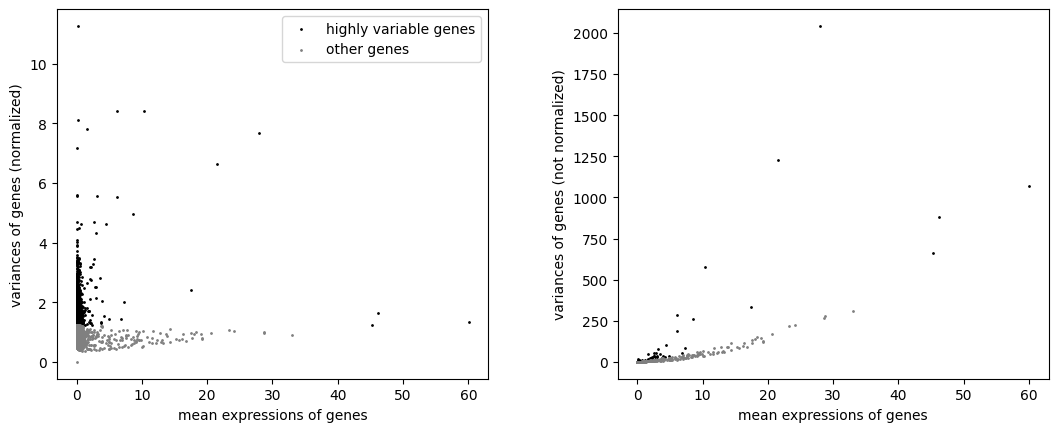

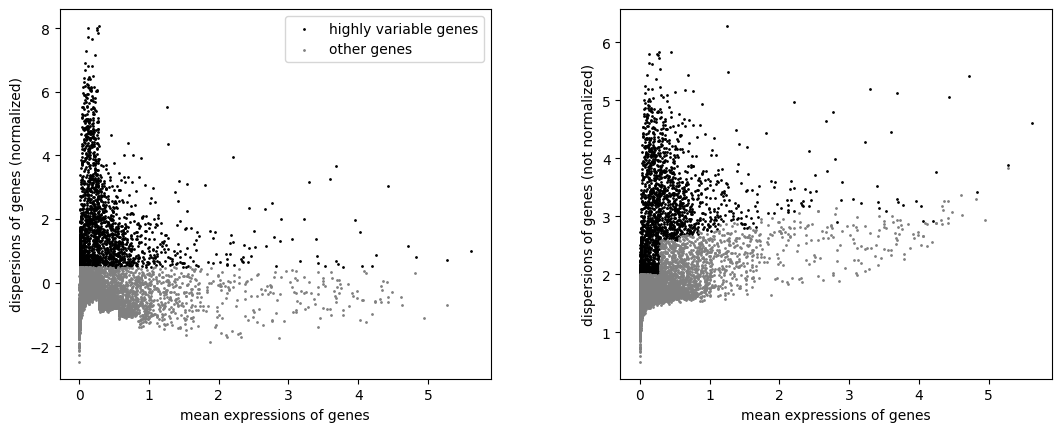

In [39]:
sc.pl.highly_variable_genes(v3)
sc.pl.highly_variable_genes(seurat)

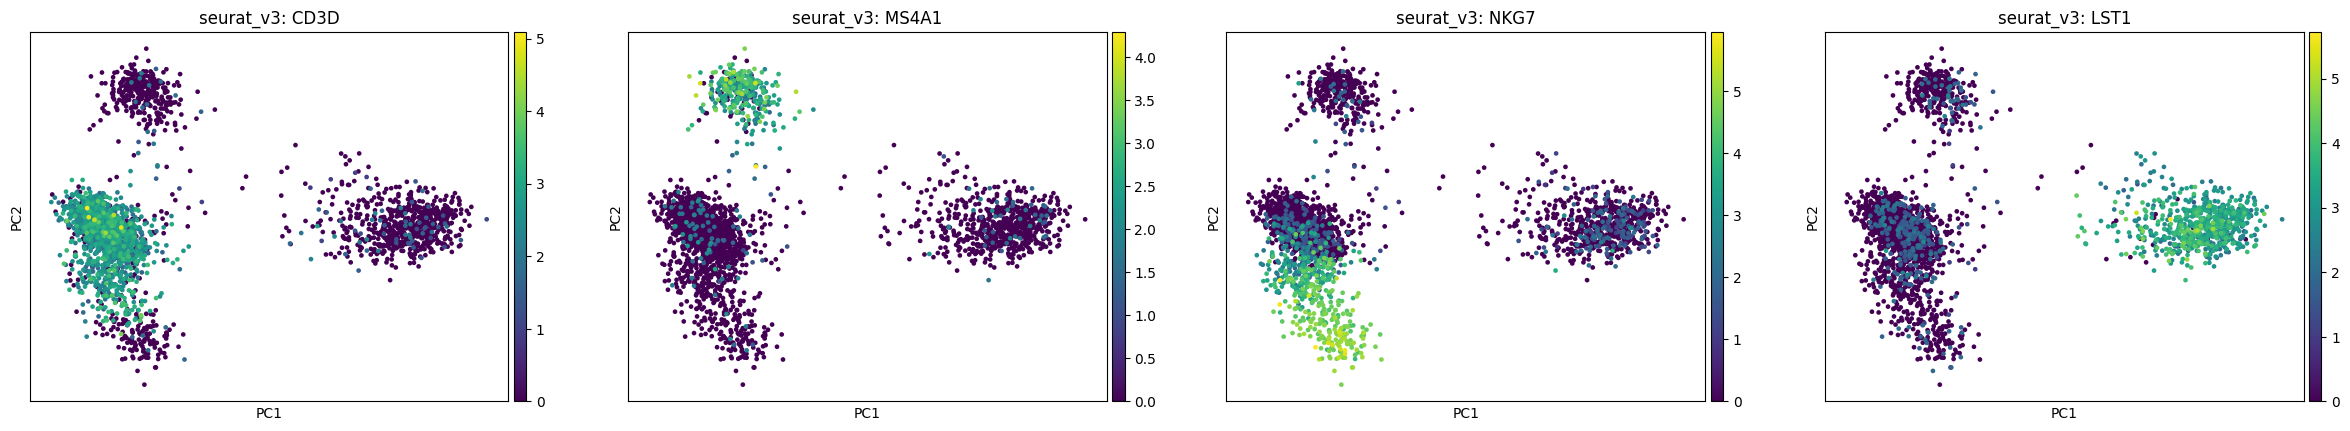

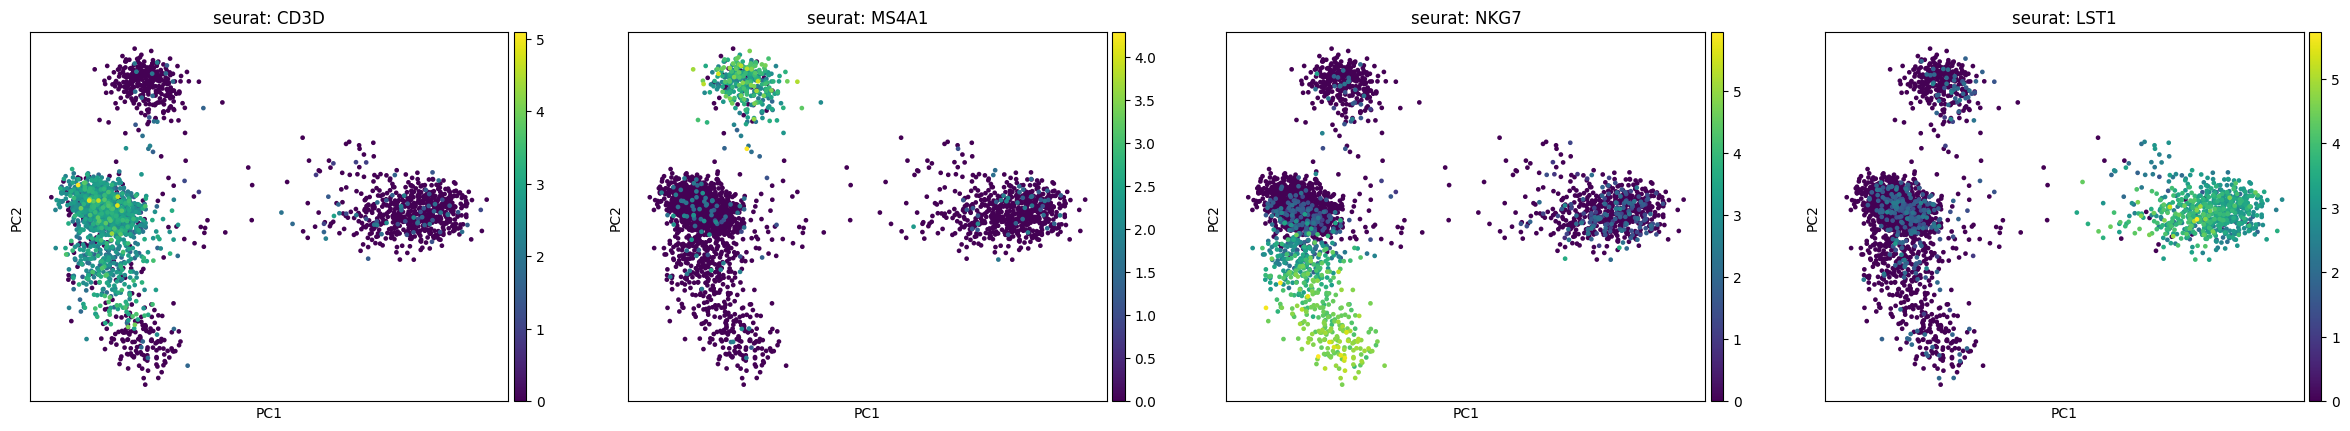

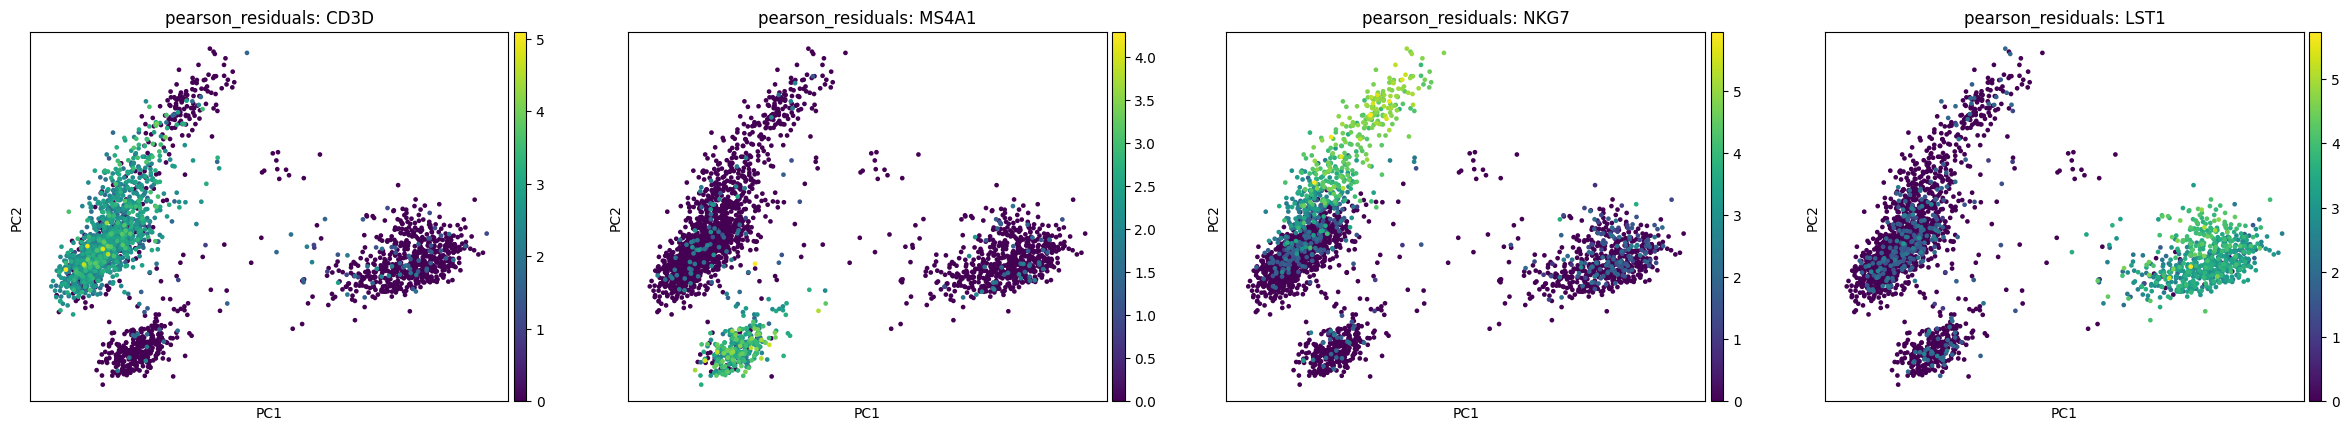

In [40]:
pcas = {}

for name, genes in hvg_sets.items():
    a = base.copy()
    a.var["highly_variable"] = a.var_names.isin(genes)
    sc.tl.pca(a, mask_var="highly_variable")
    pcas[name] = a
    sc.pl.pca(a, color=MARKERS, ncols=4, title=[f"{name}: {m}" for m in MARKERS])

In [41]:
overlap = pd.DataFrame(index=hvg_sets, columns=hvg_sets, dtype=int)

for x in hvg_sets:
    for y in hvg_sets:
        overlap.loc[x, y] = len(set(hvg_sets[x]) & set(hvg_sets[y]))

print("пересечение всех трёх:", len(set.intersection(*(set(v) for v in hvg_sets.values()))))
overlap

пересечение всех трёх: 1145


,seurat_v3,seurat,pearson_residuals
seurat_v3,2000.0,1505.0,1402.0
seurat,1505.0,2000.0,1291.0
pearson_residuals,1402.0,1291.0,2000.0


In [42]:
# куда попали маркеры и насколько методы расходятся по доле рибосомных генов
rows = []
for name, genes in hvg_sets.items():
    genes = set(genes)
    rows.append({
        "метод": name,
        "маркеры в HVG": sum(m in genes for m in MARKERS),
        "рибосомных": sum(g.startswith(("RPS", "RPL")) for g in genes),
        "митохондриальных": sum(g.startswith("MT-") for g in genes),
    })

pd.DataFrame(rows).set_index("метод")

,маркеры в HVG,рибосомных,митохондриальных
метод,,,
seurat_v3,3,4,2
seurat,3,13,1
pearson_residuals,4,70,9


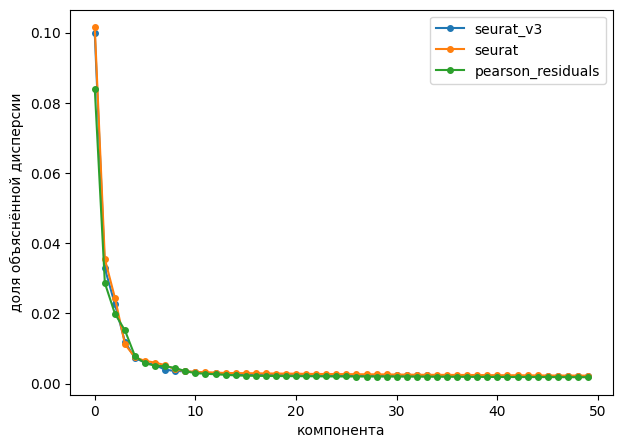

In [43]:
fig, ax = plt.subplots(figsize=(7, 5))

for name, a in pcas.items():
    ax.plot(a.uns["pca"]["variance_ratio"], "o-", ms=4, label=name)

ax.set_xlabel("компонента")
ax.set_ylabel("доля объяснённой дисперсии")
ax.legend()
plt.show()

1. seurat_v3 и seurat дают почти одинаковую картинку: два облака, B-клетки отдельным пятном. pearson_residuals размазан по диагонали — он затащил 70 рибосомных и 9 мт-генов (против 4 и 2 у seurat_v3), и это растянуло облако.

2. Группы сохраняются везде: CD3D — левое облако, MS4A1 — компактное пятно, NKG7 — группа под T-клетками, LST1 — правое облако. Метод меняет геометрию, не биологию. variance_ratio тоже совпадает: PC1 ≈ 10% у обоих seurat, 8.4% у pearson.

3. seurat_v3 пересек seurat — 1505 генов из 2000 (75%), seurat_v3 пересек pearson — 1402, seurat пересек pearson — 1291. Общих у всех трёх 1145, то есть ядро примерно в 57% набора совпадает всегда.

Ближе всего друг к другу два варианта seurat, оба ранжируют по дисперсии, разница только в шкале (counts против лог-значений). Pearson residuals дальше от обоих и дальше всего от seurat (1291): он штрафует гены по другой логике и набирает высокоэкспрессируемые — отсюда 70 рибосомных.

## Задание 3. PCA без отбора HVG

Повторите PCA, используя все гены, прошедшие QC, без ограничения набором HVG.

Сравните результат с PCA, построенным по 2000 HVG.

Используйте те же маркеры и одинаковые настройки нормализации и масштабирования данных.

**Вопросы:** Как изменилась структура клеток? Какие компоненты объясняют больше дисперсии? Почему использование всех доступных генов не обязательно делает PCA информативнее?


генов в PCA: 13714


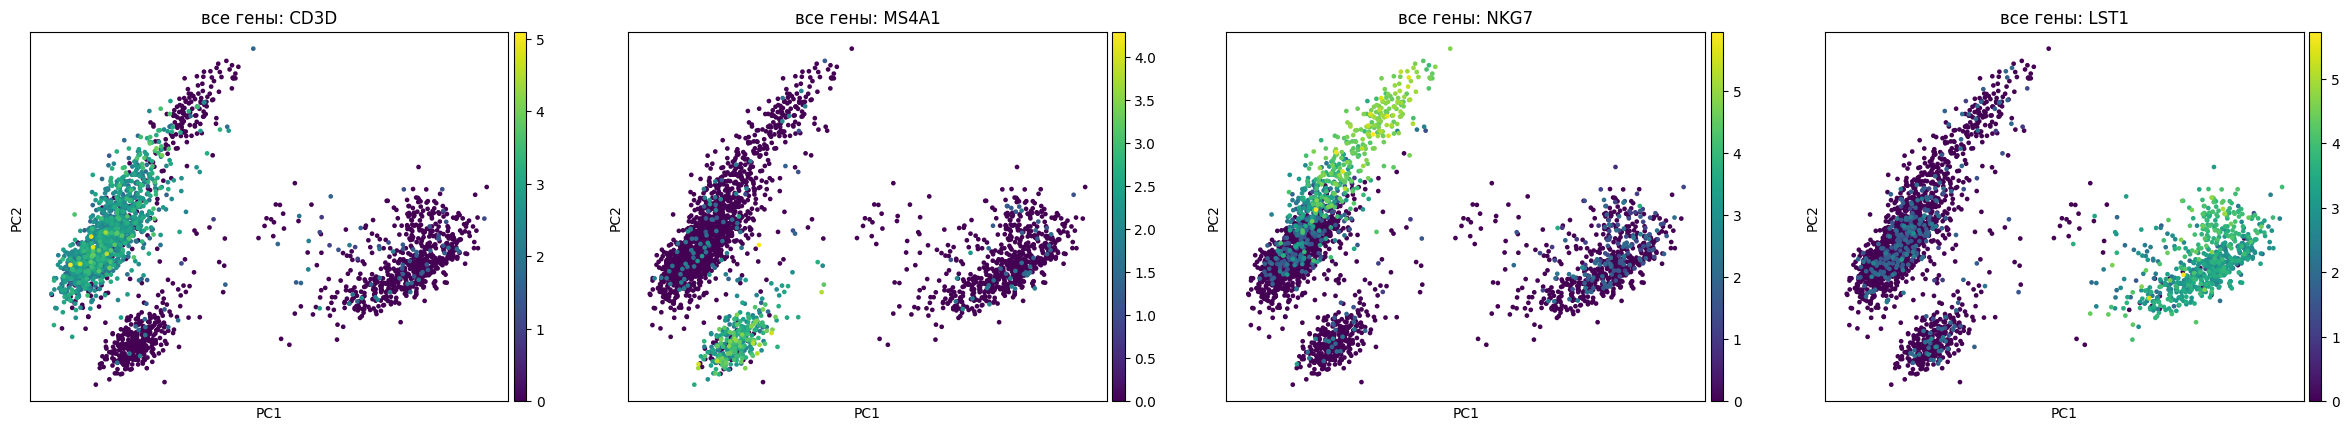

In [44]:
all_genes = base.copy()
sc.tl.pca(all_genes, mask_var=None)

print("генов в PCA:", all_genes.n_vars)
sc.pl.pca(all_genes, color=MARKERS, ncols=4, title=[f"все гены: {m}" for m in MARKERS])

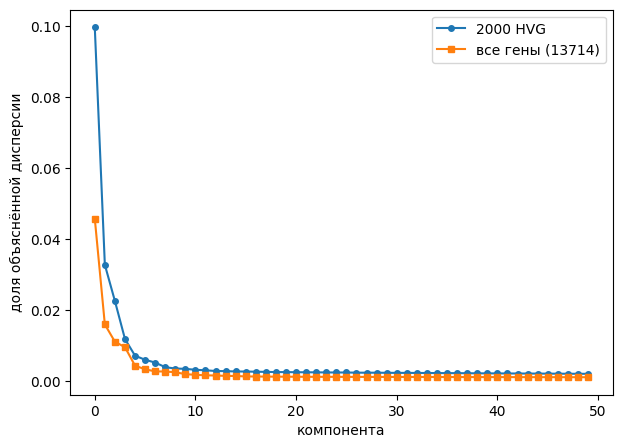

суммарно в первых 10 PC, HVG:       0.197
суммарно в первых 10 PC, все гены:  0.1


In [45]:
hv = pcas["seurat_v3"]

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(hv.uns["pca"]["variance_ratio"], "o-", ms=4, label="2000 HVG")
ax.plot(all_genes.uns["pca"]["variance_ratio"], "s-", ms=4, label=f"все гены ({all_genes.n_vars})")
ax.set_xlabel("компонента")
ax.set_ylabel("доля объяснённой дисперсии")
ax.legend()
plt.show()

print("суммарно в первых 10 PC, HVG:      ", hv.uns["pca"]["variance_ratio"][:10].sum().round(3))
print("суммарно в первых 10 PC, все гены: ", all_genes.uns["pca"]["variance_ratio"][:10].sum().round(3))

In [46]:
# насколько совпадает геометрия: корреляция координат клеток по первым компонентам
hvg_coords = hv.obsm["X_pca"]
all_coords = all_genes.obsm["X_pca"]

corr = pd.DataFrame(
    [[abs(np.corrcoef(hvg_coords[:, i], all_coords[:, j])[0, 1]).round(2) for j in range(5)]
     for i in range(5)],
    index=[f"HVG PC{i+1}" for i in range(5)],
    columns=[f"все гены PC{j+1}" for j in range(5)],
)
corr

,все гены PC1,все гены PC2,все гены PC3,все гены PC4,все гены PC5
HVG PC1,0.99,0.10,0.09,0.01,0.04
HVG PC2,0.07,0.89,0.17,0.39,0.09
HVG PC3,0.08,0.34,0.72,0.54,0.17
HVG PC4,0.02,0.22,0.50,0.65,0.40
HVG PC5,0.03,0.04,0.20,0.17,0.57


1. Крупные группы: PC1 совпадает почти идеально (корреляция 0.99), PC2 — 0.89. Маркеры разводят те же популяции: `CD3D` — верхнее левое облако, `MS4A1` — нижнее пятно, `NKG7` — верхушка, `LST1` — правое. Но дальше PC2 геометрия расходится: PC3 — 0.72, PC4 — 0.65, PC5 — 0.57, причём HVG-PC3 размазался между PC3 и PC4 полного варианта (0.72 и 0.54). То есть всё, что ниже первых двух компонент, перемешалось.

2. PC1 — 10.0% на HVG против 4.5% на всех генах, первые 10 PC — 19.7% против 10.0%. Вдвое. Это не больше сигнала от HVG, а меньше шумовой дисперсии в знаменателе: 11714 выброшенных генов добавляли дисперсию, но не структуру.

3. Гены с низкой и почти постоянной экспрессией дают шум захвата и не различают типы клеток. Они не убивают сигнал, а разбавляют его — информативные направления смешиваются с шумовыми, и это бьёт именно по средним компонентам, что и видно по развалу корреляций с PC3. Первые две компоненты слишком сильные, чтобы их расшатать, а PC3–PC5 уже съезжают — а их как раз и используют для построения соседского графа и кластеризации. Плюс считать дольше по матрице в 7 раз шире.

## Задание 4. HVG и уровень экспрессии

Получите два списка:

- Гены, отобранные как HVG.
- Гены, не попавшие в HVG.

В каждом списке найдите 50 генов с наибольшим средним количеством UMI на клетку по исходным counts.

Сравните средний уровень экспрессии, дисперсию и известные функции этих генов.

**Вопросы:** Обязательно ли HVG являются наиболее экспрессируемыми генами? Почему ген может иметь очень высокую экспрессию, но не попасть в HVG? Какие группы генов встречаются среди наиболее экспрессируемых?


In [47]:
mean_umi, var_umi = gene_means_and_vars(base.layers["counts"].tocsc())

genes = pd.DataFrame({
    "mean_umi": mean_umi,
    "var_umi": var_umi,
    "hvg": base.var_names.isin(hvg_sets["seurat_v3"]),
}, index=base.var_names)
genes["cv2"] = genes.var_umi / genes.mean_umi ** 2
genes["группа"] = np.select(
    [base.var_names.str.startswith(("RPS", "RPL")),
     base.var_names.str.startswith("MT-"),
     base.var_names.str.match(r"^HB[ABDEGMQZ]\d?$"),
     base.var_names.isin(["MALAT1", "B2M", "TMSB4X", "ACTB", "FTL", "FTH1"])],
    ["рибосомные", "митохондриальные", "гемоглобины", "housekeeping / структурные"],
    default="прочие",
)

top_hvg = genes[genes.hvg].nlargest(50, "mean_umi")
top_rest = genes[~genes.hvg].nlargest(50, "mean_umi")

print("HVG:", genes.hvg.sum(), "| не-HVG:", (~genes.hvg).sum())
top_hvg.head(15).round(3)

HVG: 2000 | не-HVG: 11714


,mean_umi,var_umi,hvg,cv2,группа
MALAT1,60.036999,1066.569946,True,0.296,housekeeping / структурные
TMSB4X,46.139999,883.349976,True,0.415,housekeeping / структурные
B2M,45.289001,659.148987,True,0.321,housekeeping / структурные
FTL,27.999001,2041.885986,True,2.605,housekeeping / структурные
FTH1,21.535000,1224.520020,True,2.640,housekeeping / структурные
ACTB,17.459000,334.397003,True,1.097,housekeeping / структурные
LYZ,10.408000,575.138977,True,5.309,прочие
CD74,8.580000,261.792999,True,3.556,прочие
S100A4,7.343000,86.244003,True,1.599,прочие
MT-CO2,6.889000,56.957001,True,1.200,митохондриальные


In [48]:
top_rest.head(15).round(3)

,mean_umi,var_umi,hvg,cv2,группа
RPL10,33.016998,307.453003,False,0.282,рибосомные
RPL13,28.774000,280.544006,False,0.339,рибосомные
RPL13A,28.643999,264.612000,False,0.322,рибосомные
RPS2,24.091999,222.751007,False,0.384,рибосомные
RPS6,23.292999,217.959000,False,0.402,рибосомные
RPS18,20.608999,166.667999,False,0.392,рибосомные
RPL11,19.285999,128.378006,False,0.345,рибосомные
RPL32,19.240000,122.027000,False,0.330,рибосомные
RPS3,19.014000,146.748993,False,0.406,рибосомные
RPL19,18.271999,149.699997,False,0.448,рибосомные


In [49]:
comparison = pd.DataFrame({
    "топ-50 среди HVG": top_hvg[["mean_umi", "var_umi", "cv2"]].mean(),
    "топ-50 среди не-HVG": top_rest[["mean_umi", "var_umi", "cv2"]].mean(),
    "все HVG": genes[genes.hvg][["mean_umi", "var_umi", "cv2"]].mean(),
    "все не-HVG": genes[~genes.hvg][["mean_umi", "var_umi", "cv2"]].mean(),
}).round(3)
comparison

,топ-50 среди HVG,топ-50 среди не-HVG,все HVG,все не-HVG
mean_umi,7.149000,14.332000,0.300000,0.151
var_umi,173.143997,94.365997,5.036000,0.628
cv2,3.951000,0.445000,191.843994,178.444


In [50]:
pd.DataFrame({
    "топ-50 HVG": top_hvg["группа"].value_counts(),
    "топ-50 не-HVG": top_rest["группа"].value_counts(),
}).fillna(0).astype(int)

,топ-50 HVG,топ-50 не-HVG
группа,,
housekeeping / структурные,6,0
митохондриальные,1,1
прочие,43,4
рибосомные,0,45


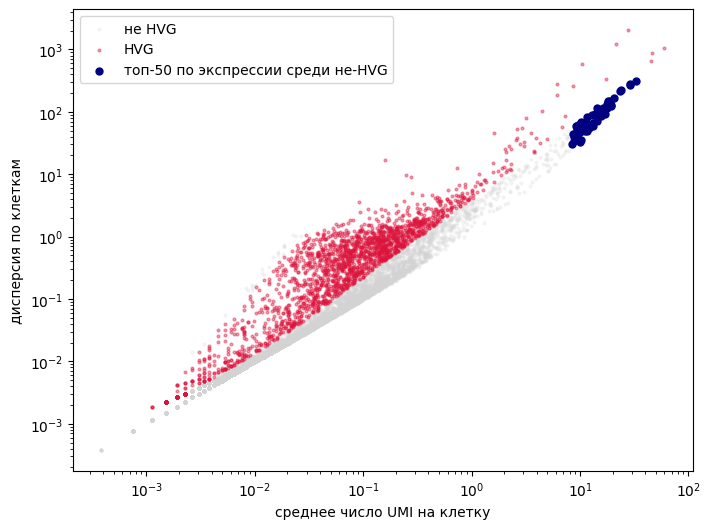

In [51]:
fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(genes.loc[~genes.hvg, "mean_umi"], genes.loc[~genes.hvg, "var_umi"],
           s=4, alpha=0.2, color="lightgrey", label="не HVG")
ax.scatter(genes.loc[genes.hvg, "mean_umi"], genes.loc[genes.hvg, "var_umi"],
           s=4, alpha=0.4, color="crimson", label="HVG")
ax.scatter(top_rest.mean_umi, top_rest.var_umi, s=25, color="navy",
           label="топ-50 по экспрессии среди не-HVG")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("среднее число UMI на клетку")
ax.set_ylabel("дисперсия по клеткам")
ax.legend()
plt.show()

1. Нет, наоборот: средняя экспрессия топ-50 среди не-HVG — 14.33 UMI на клетку против 7.15 у топ-50 среди HVG. Самые экспрессируемые гены чаще оказываются вне HVG.

2. Решающая колонка — CV²: у топ-50 не-HVG она 0.445, у топ-50 HVG — 3.951, почти в 9 раз выше. У счётных данных дисперсия растёт вместе со средним (Пуассон: Var = E, NB — быстрее), поэтому большая абсолютная `var_umi` у сильного гена ничего не значит. `seurat_v3` оценивает ожидаемую дисперсию как функцию среднего и ранжирует по остатку от этой кривой. Синие точки (топ-50 не-HVG) лежат справа и точно на общем тренде, красные HVG — выше него. Ген, одинаково высоко работающий во всех клетках, популяции не различает.

3. Среди не-HVG — 45 из 50 рибосомных (RPL10, RPL13, RPS2, RPS6...), их CV² 0.28–0.45: много и ровно везде. Среди HVG в топе 6 housekeeping/структурных (MALAT1, TMSB4X, B2M, FTL, FTH1, ACTB) и 43 «прочих» — эти прочие как раз маркеры доминирующих популяций: LYZ (CV² 5.3), S100A9 (7.5), CST3 (5.1), CD74, HLA-DRA, S100A4/A6. Высокие только в части клеток — отсюда и избыточная дисперсия.

## Задание 5. Влияние QC-метрик на PCA

Постройте несколько PCA plots для случаев:

1. Не используя фильтрацию и QC и не используя поиск HVG.
2. Не используя фильтрацию и QC, но используя поиск HVG.
3. Используя фильтрацию и QC, но не используя поиск HVG.
4. Используя фильтрацию и QC и используя поиск HVG.

Окрашивайте клетки по:

1. `total_counts` — общее число UMI клетки.
2. `n_genes_by_counts` — число обнаруженных генов.
3. `pct_counts_mt` — доля митохондриальных UMI.
4. Доле рибосомных UMI из задания 1.

Дополнительно постройте scatter plot:

- X — `total_counts`
- Y — `n_genes_by_counts`
- цвет — `pct_counts_mt`

Теперь повторите анализ не используя фильтрацию и QC но используя HVG

**Вопросы:** Связано ли положение клеток на PCA с количеством зарегистрированных UMI? Есть ли направления, вдоль которых меняется доля митохондриальных транскриптов? Можно ли по этим графикам заподозрить, что технические факторы влияют на главные компоненты?

In [52]:
COLOR_BY = ["total_counts", "n_genes_by_counts", "pct_counts_mt", "pct_counts_ribo"]

variants = {}
for qc in (False, True):
    for hvg in (False, True):
        label = f"QC={'да' if qc else 'нет'}, HVG={'да' if hvg else 'нет'}"
        a = preprocess(qc=qc, hvg=hvg)
        sc.tl.pca(a, mask_var="highly_variable" if hvg else None)
        variants[label] = a
        print(label, "| клеток:", a.n_obs, "| генов в PCA:",
              int(a.var.highly_variable.sum()) if hvg else a.n_vars)

QC=нет, HVG=нет | клеток: 2700 | генов в PCA: 16634
QC=нет, HVG=да | клеток: 2700 | генов в PCA: 2000
QC=да, HVG=нет | клеток: 2638 | генов в PCA: 13714
QC=да, HVG=да | клеток: 2638 | генов в PCA: 2000


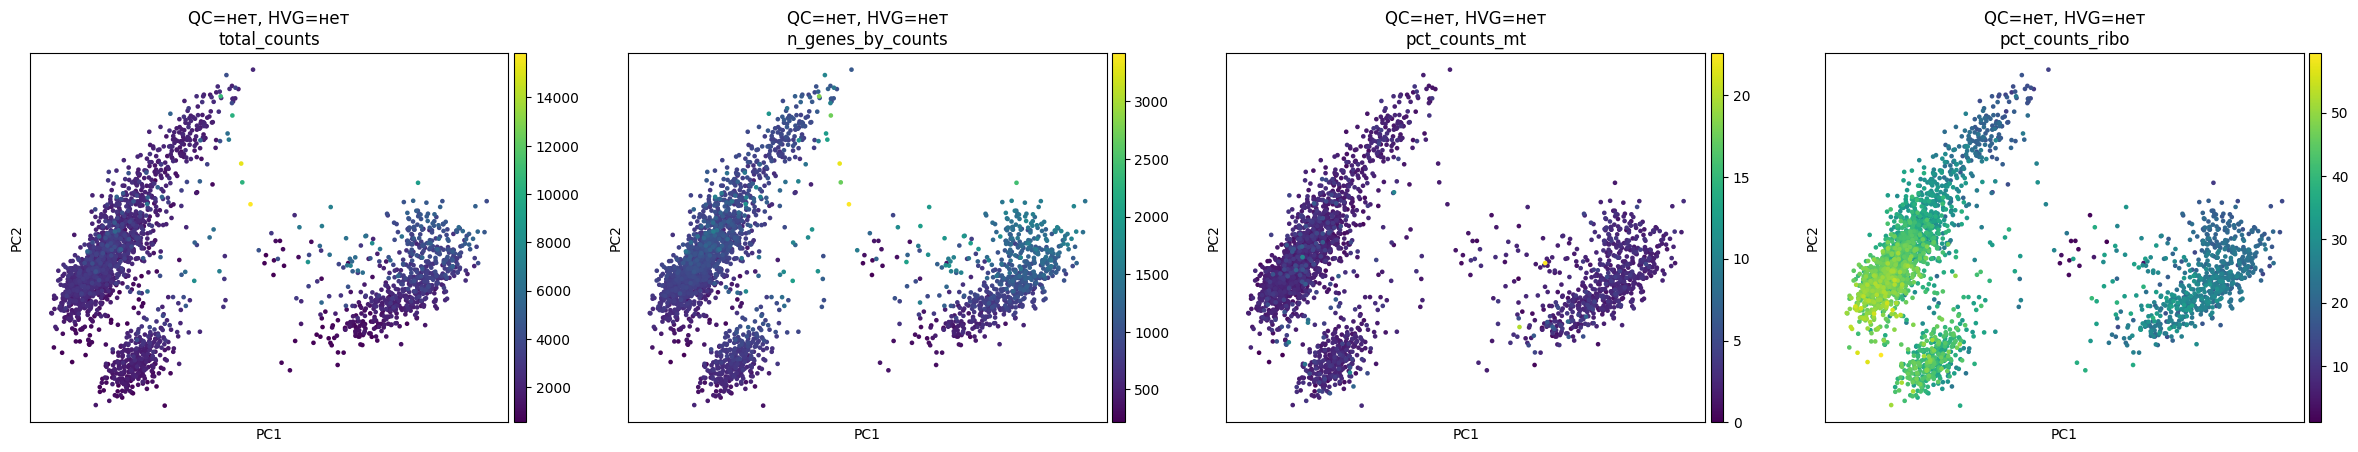

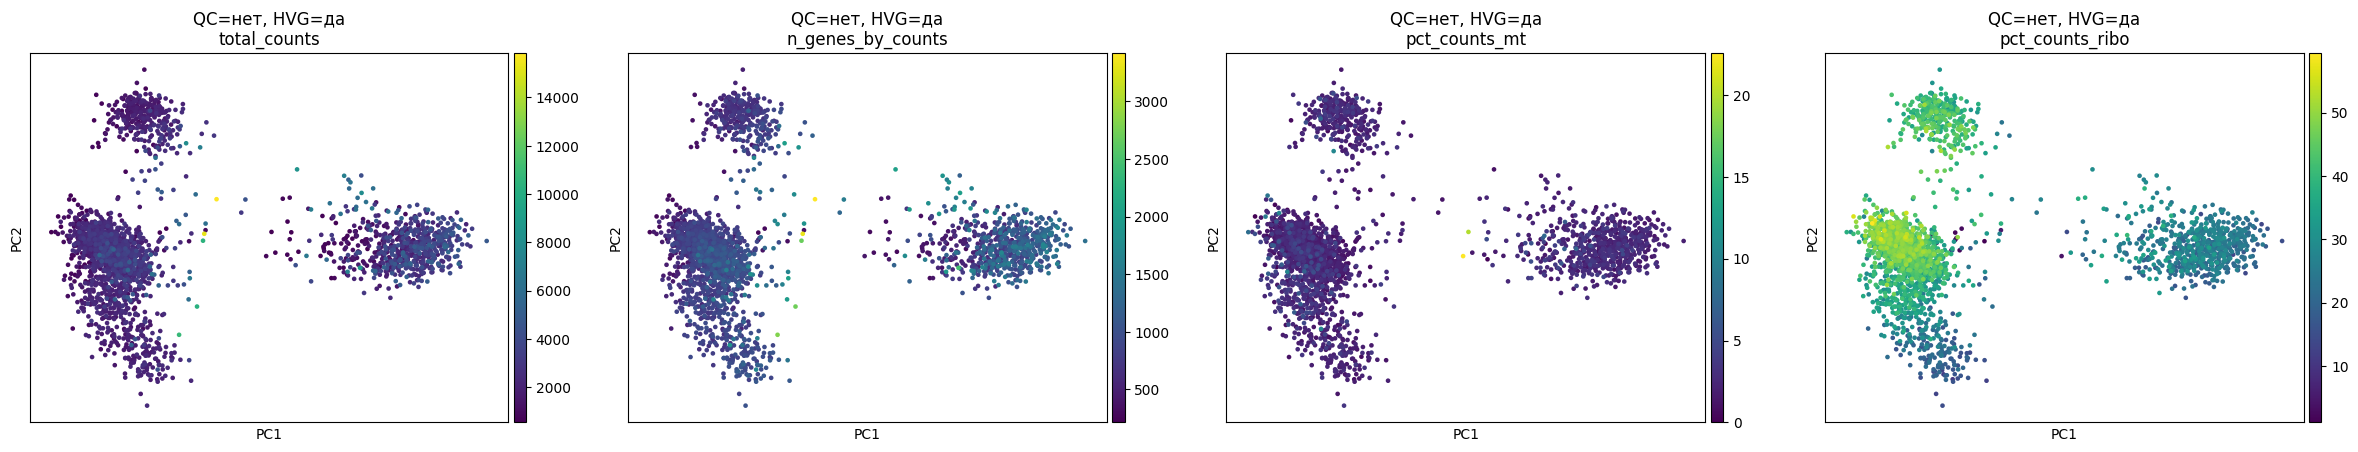

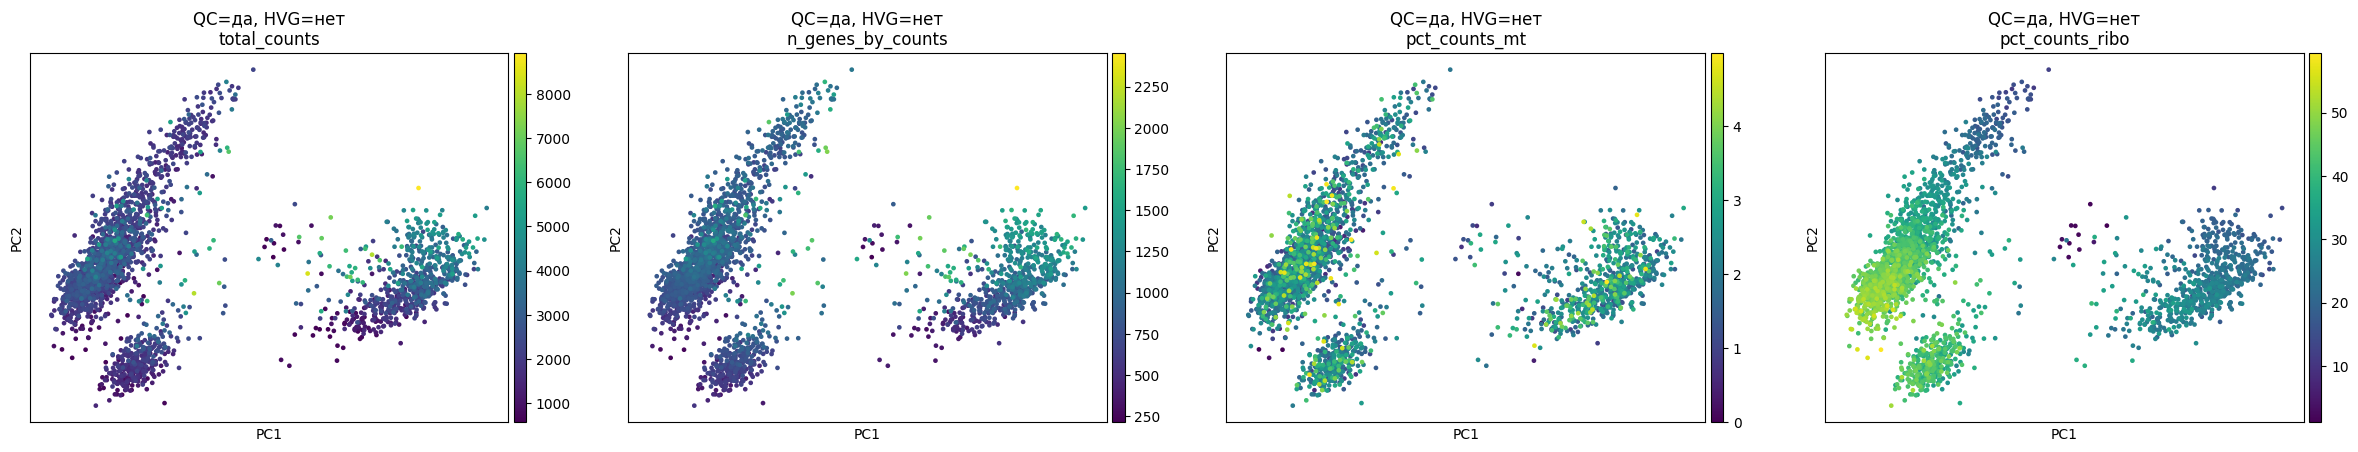

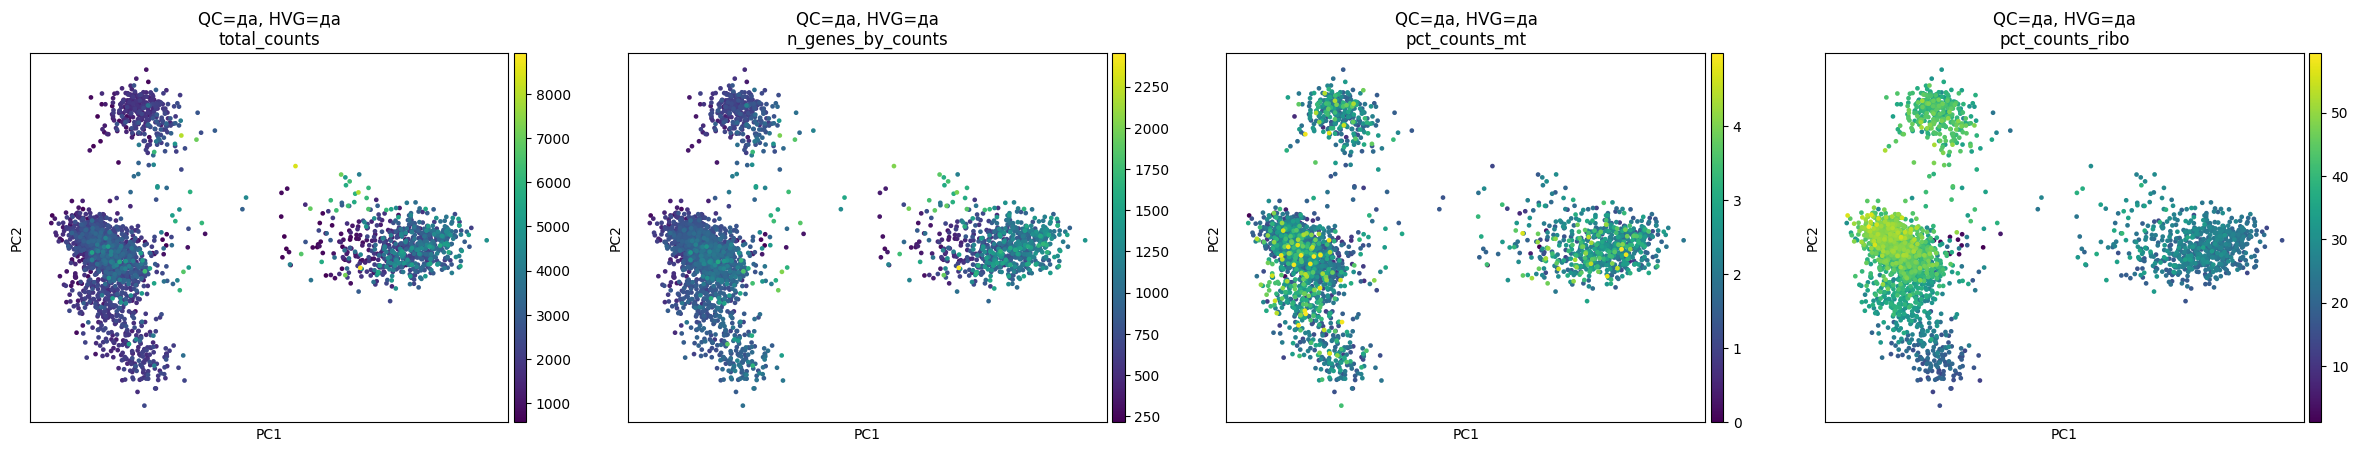

In [53]:
for label, a in variants.items():
    sc.pl.pca(a, color=COLOR_BY, ncols=4, title=[f"{label}\n{c}" for c in COLOR_BY])

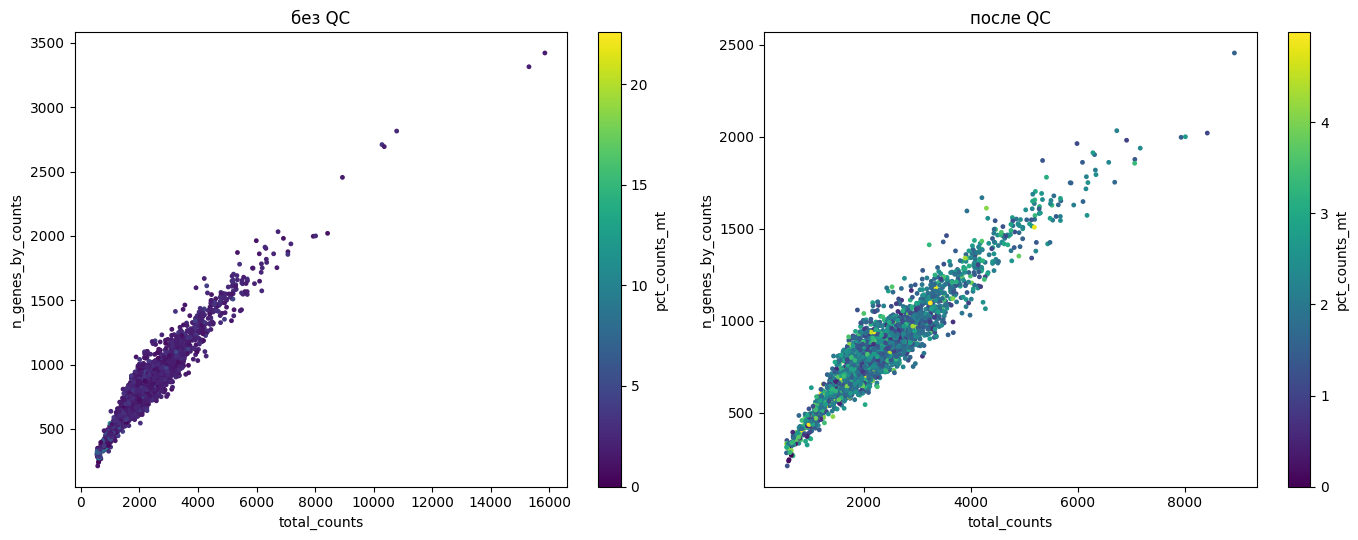

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, (label, a) in zip(axes, [("без QC", variants["QC=нет, HVG=да"]),
                                 ("после QC", variants["QC=да, HVG=да"])]):
    sp = ax.scatter(a.obs.total_counts, a.obs.n_genes_by_counts,
                    c=a.obs.pct_counts_mt, s=6, cmap="viridis")
    ax.set_title(label)
    ax.set_xlabel("total_counts")
    ax.set_ylabel("n_genes_by_counts")
    fig.colorbar(sp, ax=ax, label="pct_counts_mt")

fig.tight_layout()
plt.show()

In [56]:
rows = {}
for label, a in variants.items():
    coords = a.obsm["X_pca"]
    rows[label] = {
        f"{metric} ~ PC{i+1}": round(float(np.corrcoef(coords[:, i], a.obs[metric])[0, 1]), 2)
        for metric in ["total_counts", "pct_counts_mt"]
        for i in range(3)
    }

pd.DataFrame(rows).T

,total_counts ~ PC1,total_counts ~ PC2,total_counts ~ PC3,pct_counts_mt ~ PC1,pct_counts_mt ~ PC2,pct_counts_mt ~ PC3
"QC=нет, HVG=нет",0.28,0.29,-0.60,0.11,-0.06,0.26
"QC=нет, HVG=да",0.30,-0.08,0.10,0.08,-0.01,0.03
"QC=да, HVG=нет",0.31,0.22,-0.50,0.16,-0.02,0.14
"QC=да, HVG=да",0.33,-0.08,0.04,0.15,-0.01,0.08


1. Да, но умеренная и устойчивая: total_counts ~ PC1 даёт 0.28–0.33 во всех четырёх вариантах, QC и HVG на неё почти не влияют. Визуально на панелях total_counts явного градиента нет — окраска почти однородная, выделяются лишь единичные яркие точки с 10–16 тыс. UMI.

total_counts около PC3 равно −0.60 без HVG и −0.50 с QC без HVG, но падает до 0.10 и 0.04, как только включается отбор HVG. То есть глубина библиотеки уходит в третью компоненту, и именно HVG её оттуда убирает — фильтрация по QC тут почти не помогает (−0.60 -> −0.50).

2. Выраженного направления нет: корреляции с PC1 всего 0.08–0.16, с PC2 около нуля. Слабый след виден только в PC3 без HVG (0.26). На панелях pct_counts_mt без QC клетки с высокими значениями (до 22%) разбросаны по облаку, а не вытянуты в «ус». После QC шкала сжимается с 22% до 4.8% — градиент мы срезали порогом, а не объяснили.

3. Самый яркий градиент на всех панелях даёт pct_counts_ribo: левое облако жёлтое (45–55%), правое бирюзовое (20–30%), то есть метрика меняется ровно вдоль PC1. Но это не артефакт — это и есть ось «лимфоциты ↔ моноциты», та же, что подсвечивают CD3D и LST1. Хороший пример, что градиент QC-метрики вдоль компоненты сам по себе ничего не доказывает: надо смотреть, не совпадает ли он с биологической осью.


## Задание 6. Какие гены формируют главные компоненты?

PCA строит новые признаки как линейные комбинации исходных генов.

Для первой компоненты:

$$
PC_1=a_1Z_1+a_2Z_2+\ldots+a_nZ_n
$$

Коэффициенты $a_i$ называются *loadings*.

Получите 10 генов с наибольшими положительными и 10 с наиболее отрицательными loadings для PC1 и PC2.

Постройте график loadings и графики экспрессии нескольких найденных генов на PCA.

**Вопросы:** Какие гены сильнее всего определяют PC1 и PC2? Связаны ли они с иммунными клеточными популяциями, клеточным циклом или QC-метриками? Можно ли биологически интерпретировать главные компоненты на основании этих генов?

In [57]:
hv = pcas["seurat_v3"]
loadings = pd.DataFrame(hv.varm["PCs"][:, :2], index=hv.var_names, columns=["PC1", "PC2"])

extremes = {}
for pc in ["PC1", "PC2"]:
    ranked = loadings[pc].sort_values()
    extremes[f"{pc} (−)"] = ranked.head(10).index.tolist()
    extremes[f"{pc} (+)"] = ranked.tail(10).iloc[::-1].index.tolist()

pd.DataFrame(extremes)

,PC1 (−),PC1 (+),PC2 (−),PC2 (+)
0,LTB,LYZ,NKG7,HLA-DRA
1,IL32,CST3,S100A4,CD74
2,MALAT1,S100A9,CCL5,HLA-DPB1
3,IL7R,TYROBP,IL32,HLA-DRB1
4,CCL5,S100A8,GNLY,CD79A
5,CD2,LGALS1,CTSW,HLA-DPA1
6,CTSW,AIF1,GZMA,HLA-DQA1
7,STK17A,LST1,CST7,HLA-DQB1
8,ACAP1,FCER1G,SRGN,CD79B
9,CD247,FCN1,ANXA1,HLA-DRB5


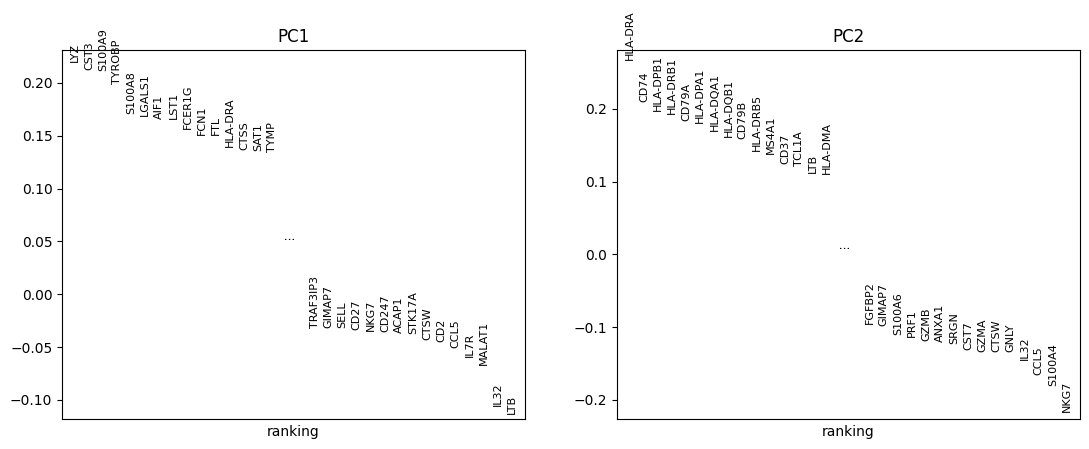

In [58]:
sc.pl.pca_loadings(hv, components="1,2")

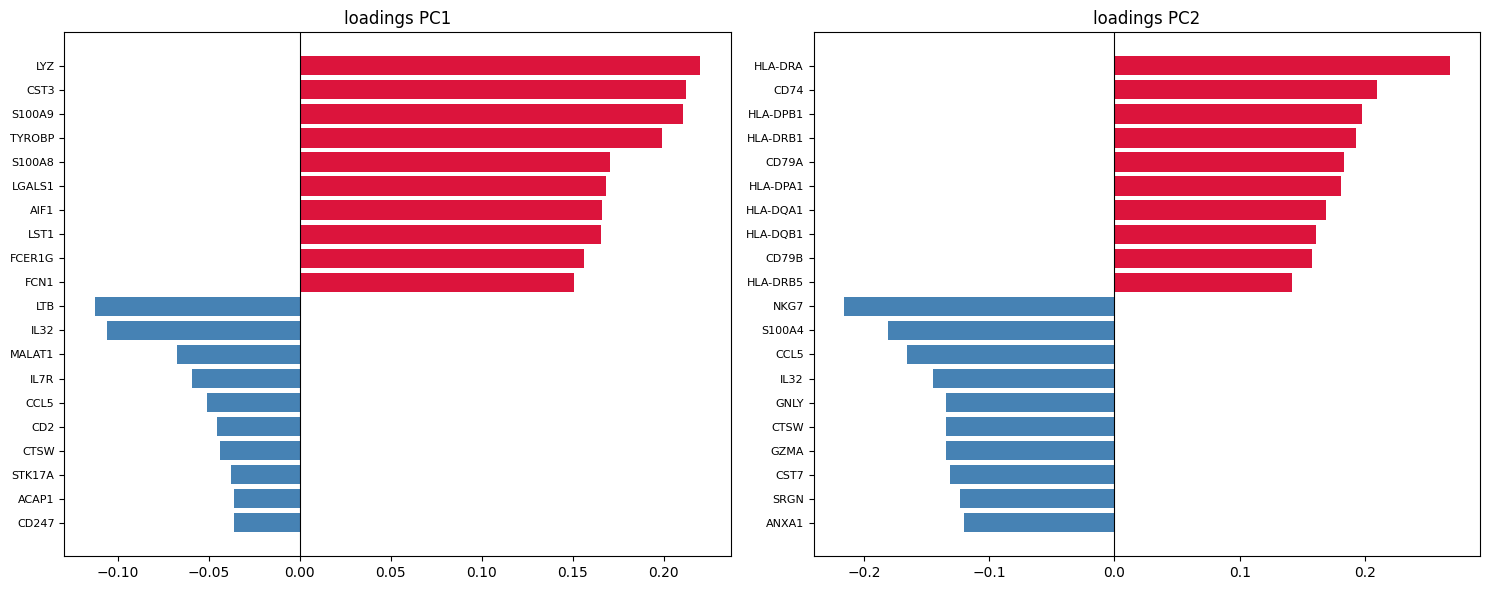

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, pc in zip(axes, ["PC1", "PC2"]):
    picked = extremes[f"{pc} (−)"][::-1] + extremes[f"{pc} (+)"][::-1]
    values = loadings.loc[picked, pc]
    ax.barh(range(len(picked)), values,
            color=["steelblue" if v < 0 else "crimson" for v in values])
    ax.set_yticks(range(len(picked)))
    ax.set_yticklabels(picked, fontsize=8)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"loadings {pc}")

fig.tight_layout()
plt.show()

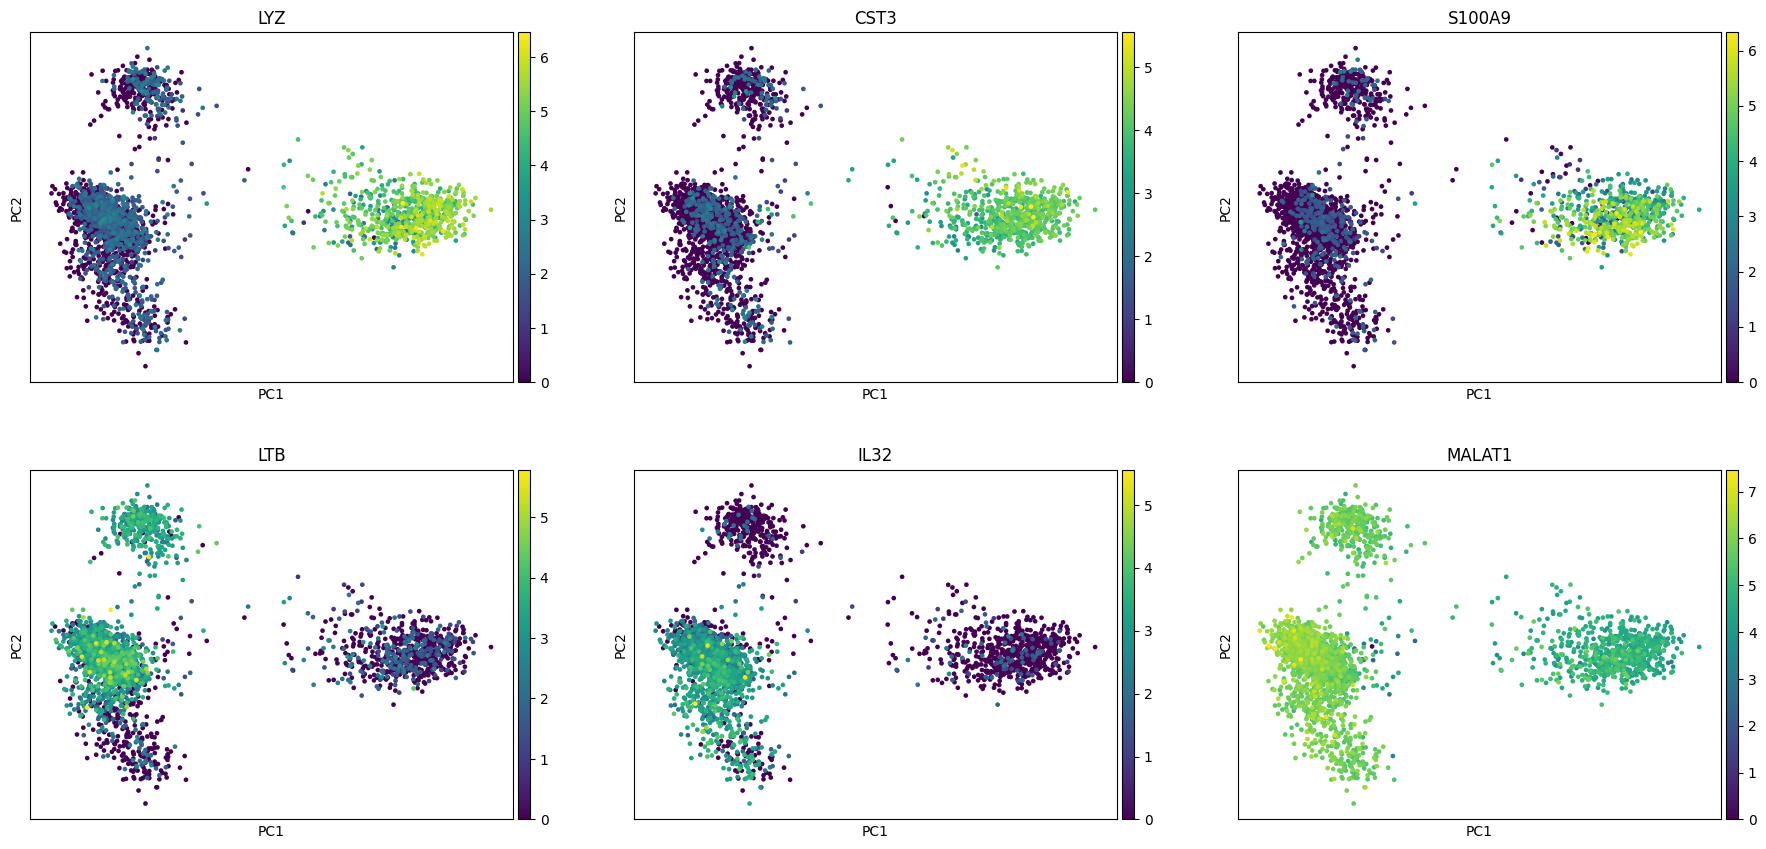

In [60]:
picked = extremes["PC1 (+)"][:3] + extremes["PC1 (−)"][:3]
sc.pl.pca(hv, color=picked, ncols=3)

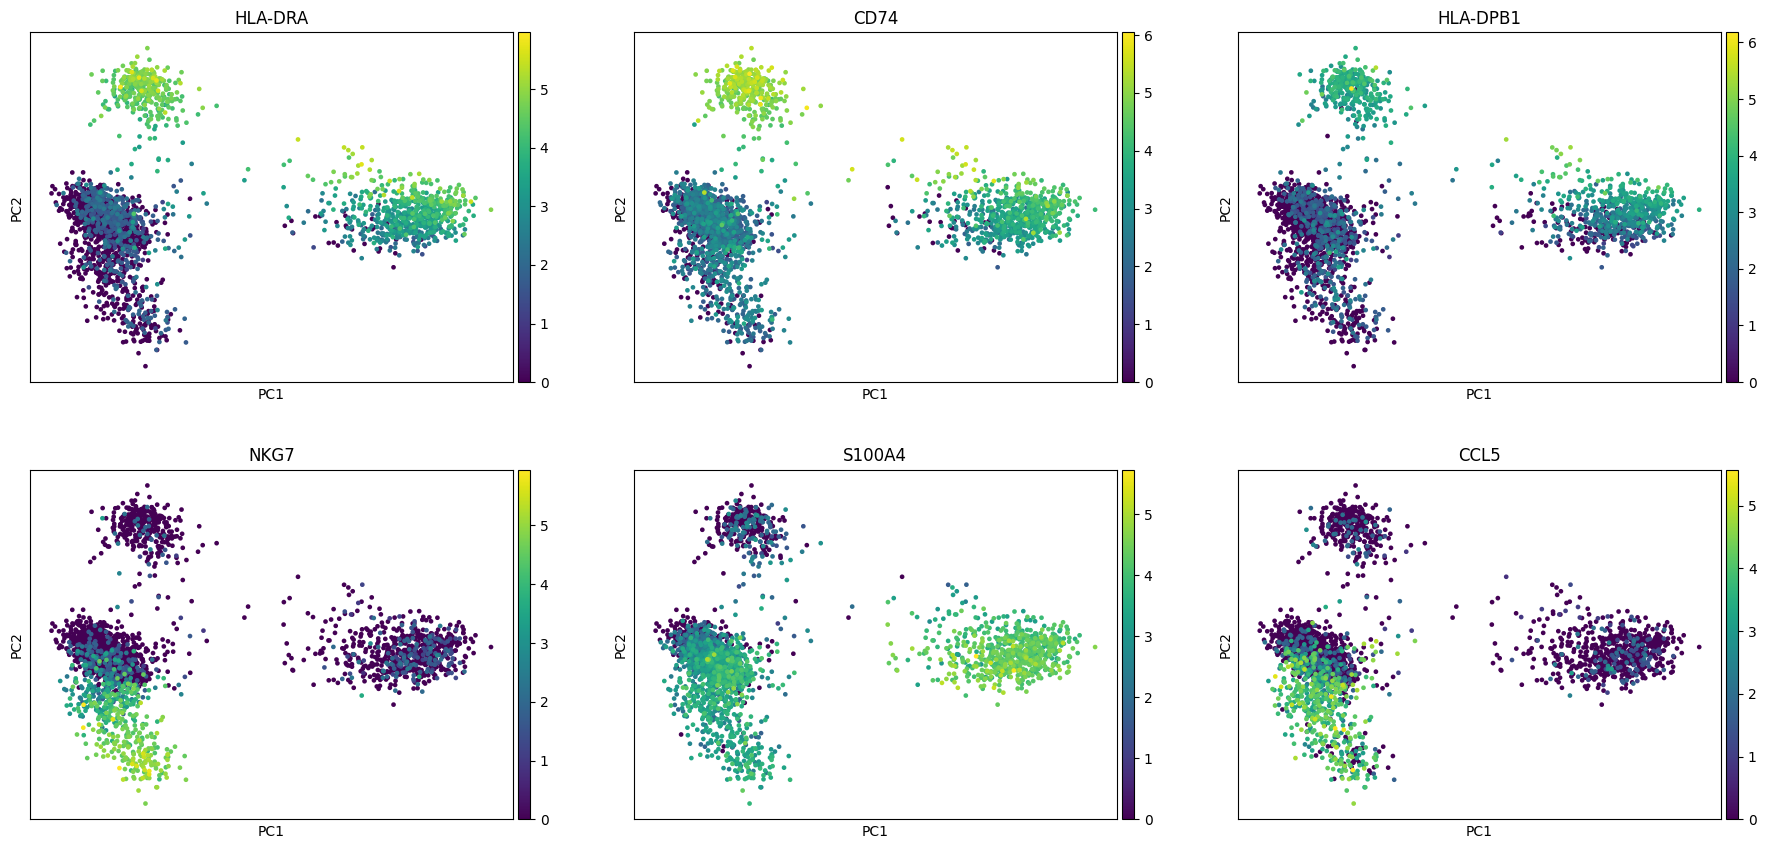

In [61]:
picked = extremes["PC2 (+)"][:3] + extremes["PC2 (−)"][:3]
sc.pl.pca(hv, color=picked, ncols=3)

In [62]:
top_loading_genes = set(sum(extremes.values(), []))

print("рибосомные:", sorted(g for g in top_loading_genes if g.startswith(("RPS", "RPL"))))
print("митохондриальные:", sorted(g for g in top_loading_genes if g.startswith("MT-")))
print("всего генов в списках:", len(top_loading_genes))

рибосомные: []
митохондриальные: []
всего генов в списках: 37


1. Гены PC1. Плюс: LYZ (0.22), CST3, S100A9, TYROBP, S100A8, LGALS1, AIF1, LST1, FCER1G, FCN1 — весь список миелоидный. Минус: LTB (−0.11), IL32, MALAT1, IL7R, CCL5, CD2, CTSW, STK17A, ACAP1, CD247 — T- и NK-клеточный. Нагрузки асимметричны: справа до 0.22, слева только до −0.11, то есть моноцитарная программа «толкает» компоненту сильнее.
Гены PC2. Плюс: HLA-DRA (0.27), CD74, HLA-DPB1, HLA-DRB1, CD79A, HLA-DPA1, HLA-DQA1, HLA-DQB1, CD79B, HLA-DRB5 — MHC-II плюс B-клеточный рецепторный комплекс. Минус: NKG7 (−0.21), S100A4, CCL5, IL32, GNLY, CTSW, GZMA, CST7, SRGN, ANXA1 — цитотоксическая гранзим-перфориновая программа.

2. Связь с популяциями / циклом / QC. С популяциями прямая, графики экспрессии это подтверждают: LYZ, CST3, S100A9 светятся в правом облаке, LTB и IL32 — в левом; HLA-DRA, CD74, HLA-DPB1 — в верхнем пятне, NKG7 и CCL5 — в нижнем. Генов цикла в списках нет: PBMC в основном покоящиеся клетки, пролиферирующей фракции почти нет. С QC тоже чисто — проверка дала пустые списки, ни одного рибосомного и ни одного митохондриального гена из 37.

Единственное исключение — MALAT1 на третьем месте по отрицательному вкладу в PC1. Это не маркер типа клеток, а ядерная lncRNA, её доля отражает сохранность цитоплазмы. Слабый технический след в PC1 всё-таки есть.

3. Интерпретация. Для первых двух компонент однозначная: PC1 — ось «миелоидные ↔ лимфоидные», PC2 — «антигенпрезентирующие (B + MHC-II) ↔ цитотоксические (NK/CD8)». На картинке это даёт три группы: моноциты справа, B-клетки сверху слева, T/NK снизу слева.

## Задание 7
- Постройте график PCA не используя логарифмирование log1p
- Постройте график PCA не используя логарифмирование log1p и нормализацию normalize
- Попробуйте дополнительно к нормализации и логарифмированию использовать `sc.pp.scale(adata)`

`sc.pp.scale(adata)` делает стандартизацию генов по столбцам клеток.

**Вопросы:** Что сильнее влияет на PCA - нормализация или логарифмирование? Сильно ли помогает scale? Что нам даёт каждая процедура: логарифмирование, нормализация, стандартизация; как они влияют на PCA? Все ли их нужно делать перед PCA?

In [67]:
transforms = {}

transforms["сырые counts"] = preprocess(normalize=False, log=False)
transforms["только normalize"] = preprocess(log=False)
transforms["normalize + log1p"] = preprocess()

scaled = preprocess()
scaled.raw = scaled          # чтобы sc.pl.pca раскрашивал по log-значениям, а не по z-оценкам
sc.pp.scale(scaled, max_value=10)
transforms["normalize + log1p + scale"] = scaled

for label, a in transforms.items():
    mask = "highly_variable" if "highly_variable" in a.var else None
    sc.tl.pca(a, mask_var=mask)
    print(label, "| максимум в X:", round(float(a.X.max()), 2))

/usr/lib/python3.13/functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


сырые counts | максимум в X: 419.0
только normalize | максимум в X: 1752.9
normalize + log1p | максимум в X: 7.47
normalize + log1p + scale | максимум в X: 10.0


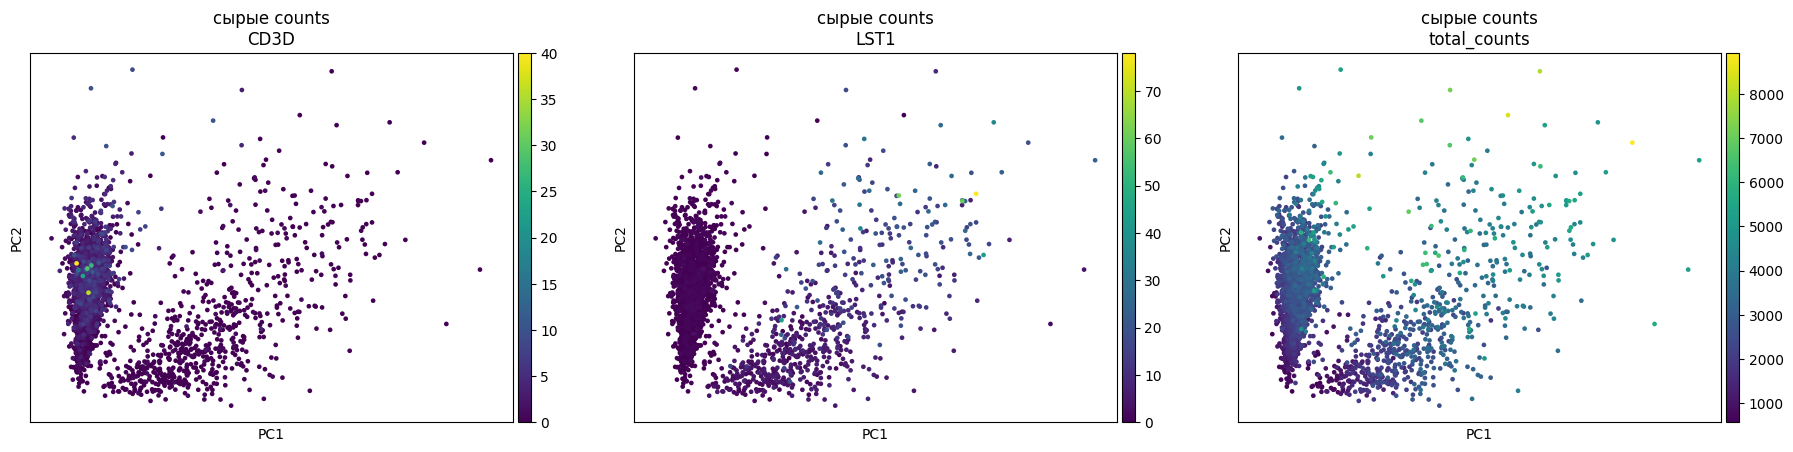

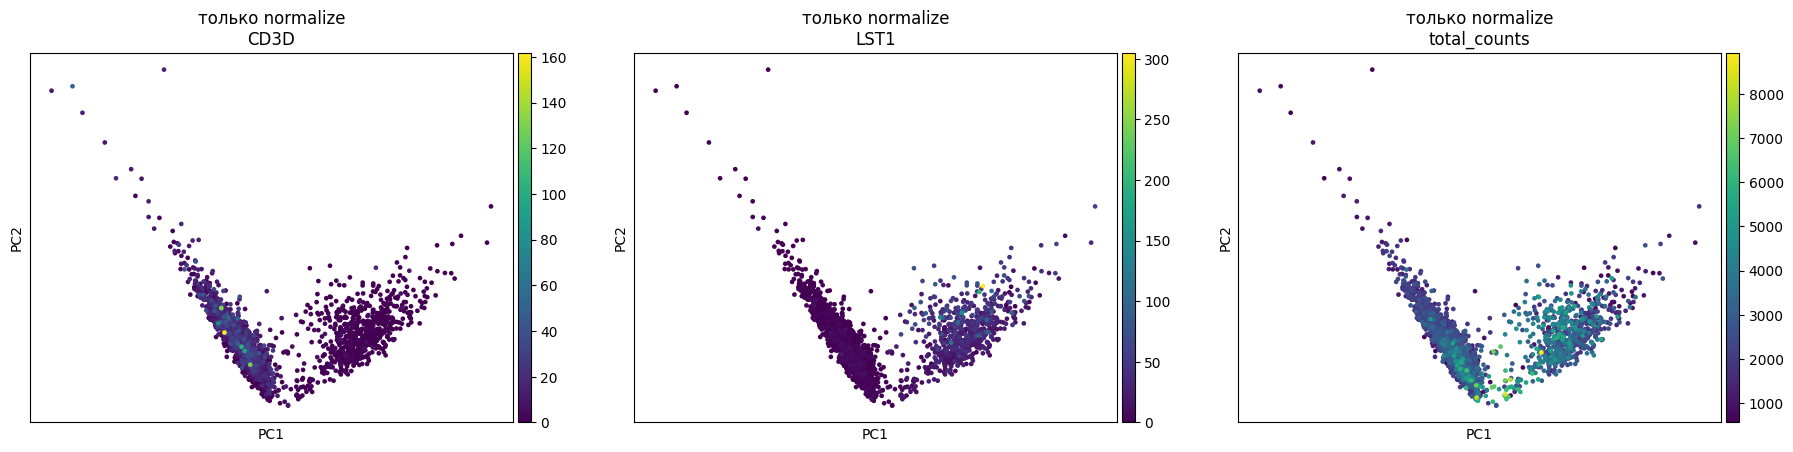

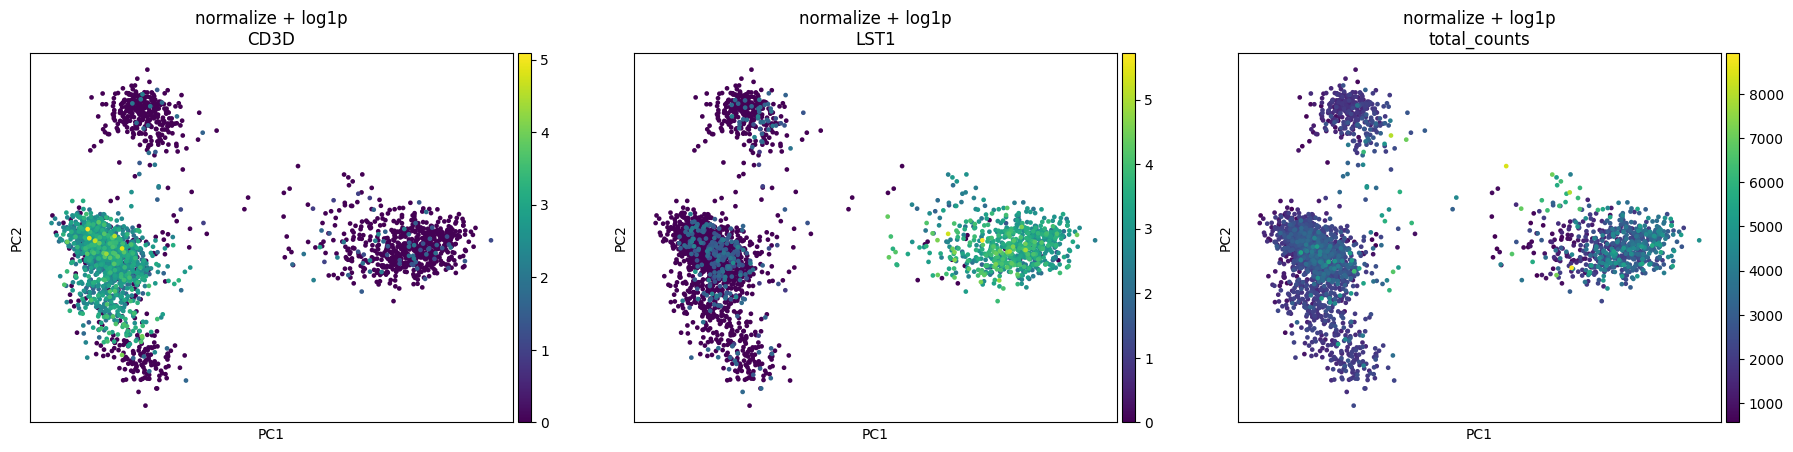

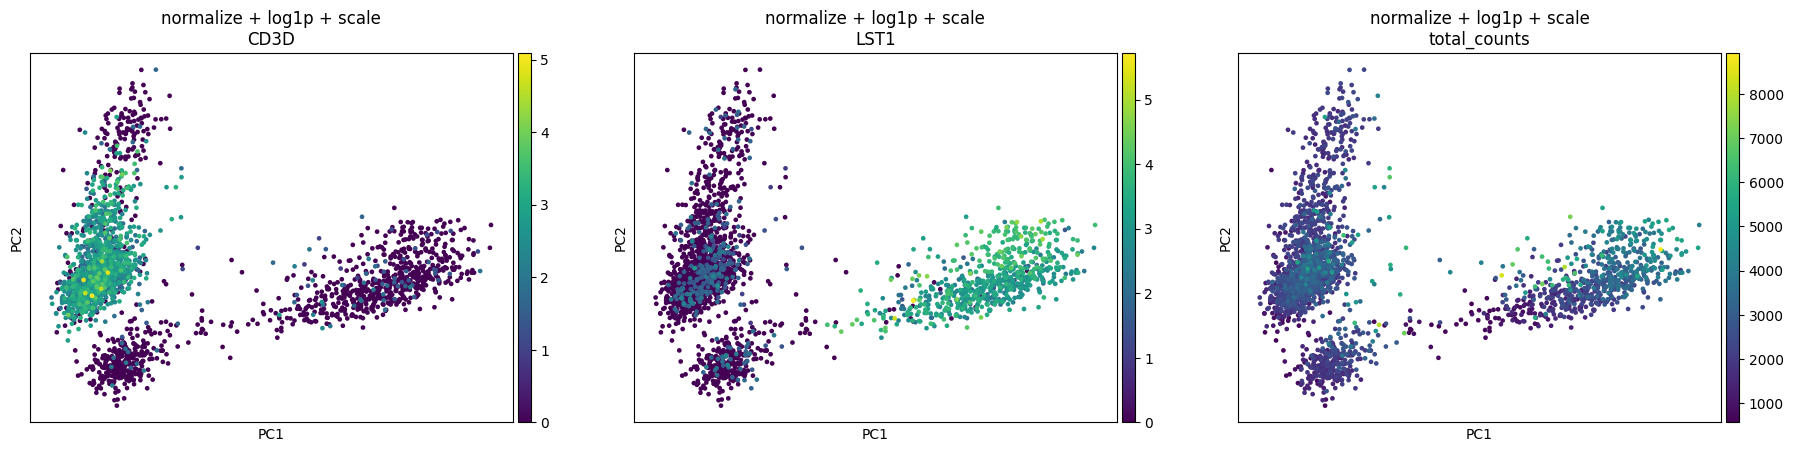

In [68]:
for label, a in transforms.items():
    sc.pl.pca(a, color=["CD3D", "LST1", "total_counts"], ncols=3,
              title=[f"{label}\n{c}" for c in ["CD3D", "LST1", "total_counts"]])

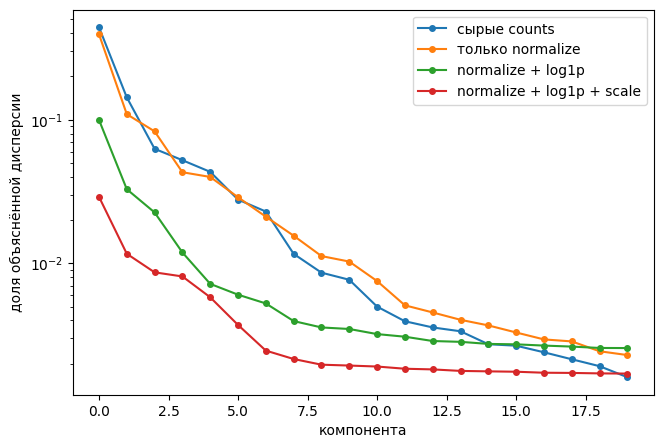

,"PC1, %","первые 10 PC, %","corr(PC1, total_counts)"
сырые counts,44.1,82.1,0.57
только normalize,39.4,75.6,0.23
normalize + log1p,10.0,19.7,0.33
normalize + log1p + scale,2.9,7.6,0.38


In [69]:
fig, ax = plt.subplots(figsize=(7.5, 5))

for label, a in transforms.items():
    ax.plot(a.uns["pca"]["variance_ratio"][:20], "o-", ms=4, label=label)

ax.set_xlabel("компонента")
ax.set_ylabel("доля объяснённой дисперсии")
ax.set_yscale("log")
ax.legend()
plt.show()

pd.DataFrame({
    label: {
        "PC1, %": round(100 * float(a.uns["pca"]["variance_ratio"][0]), 1),
        "первые 10 PC, %": round(100 * float(a.uns["pca"]["variance_ratio"][:10].sum()), 1),
        "corr(PC1, total_counts)": round(
            float(np.corrcoef(a.obsm["X_pca"][:, 0], a.obs.total_counts)[0, 1]), 2),
    }
    for label, a in transforms.items()
}).T

1. Они чинят разные вещи, и по числам это видно отдельно.
Нормализация убирает связь с глубиной: `corr(PC1, total_counts)` падает с 0.57 на сырых counts до 0.23. Но на картинку это почти не влияет — облако осталось той же V-образной «кометой», CD3D и LST1 нигде не светятся, клетки не разделяются.
Логарифм меняет именно структуру: PC1 падает с 39.4% до 10.0%, первые 10 PC — с 75.6% до 19.7%, и вместо кометы появляются три чёткие группы с маркерами на местах. То есть на вид PCA сильнее влияет `log1p`; на связь с техникой — нормализация.
Без логарифма PC1 съедает 40–44% дисперсии просто потому, что её создают несколько генов с огромными counts (MALAT1, рибосомные, ACTB). Это не сигнал, а шкала.

2. Заметного выигрыша нет. Группы остались, но границы размылись и между облаками появился «мостик» из клеток. PC1 упал до 2.9%, первые 10 PC — до 7.6%: дисперсия размазалась по многим компонентам, потому что редкие шумные гены получили тот же вес, что и сильные. И связь с глубиной не улучшилась — `corr(PC1, total_counts)` выросла с 0.33 до 0.38. На PBMC стандартизация скорее не нужна; она помогает, когда надо вытащить мелкую популяцию с редким маркером.

3. Нормализация — делает клетки сравнимыми, убирая размер библиотеки (0.57 → 0.23);
логарифмирование — стабилизирует дисперсию и переводит данные в аддитивную шкалу: разница «в 2 раза» становится одинаковым расстоянием при любом уровне экспрессии, что и нужно линейному методу;
стандартизация — выравнивает вклад генов, превращая PCA по ковариации в PCA по корреляции.

4. Нормализация и логарифм — да, это минимум. Scale опционален: в пайплайне Seurat он обязателен, в scanpy-туториалах его часто пропускают. Есть и путь вообще без всего этого — pearson residuals (`sc.experimental.pp.normalize_pearson_residuals`) или вероятностные модели вроде scVI, где стабилизация дисперсии встроена в модель.

## Дополнительное задание. Клеточный цикл и PCA

Используйте наборы генов фаз S и G2/M, чтобы вычислить оценки активности программ клеточного цикла для каждой клетки.

Определите предполагаемую фазу клеточного цикла и постройте PCA, окрашенный по:

- `S_score`
- `G2M_score`
- `phase`

**Вопросы:** Разделяются ли клетки по фазам клеточного цикла? Можно ли обнаружить связь клеточного цикла с PC1 или PC2? Почему клетки одного типа могут отличаться по экспрессии генов клеточного цикла?

In [70]:
S_GENES = [
    "MCM5",
    "PCNA",
    "TYMS",
    "FEN1",
    "MCM2",
    "MCM4",
    "RRM1",
    "UNG",
    "GINS2",
    "MCM6",
    "CDCA7",
    "DTL",
    "PRIM1",
    "UHRF1",
    "MLF1IP",
    "CENPU",
    "HELLS",
    "RFC2",
    "RPA2",
    "NASP",
    "RAD51AP1",
    "GMNN",
    "WDR76",
    "SLBP",
    "CCNE2",
    "UBR7",
    "POLD3",
    "MSH2",
    "ATAD2",
    "RAD51",
    "RRM2",
    "CDC45",
    "CDC6",
    "EXO1",
    "TIPIN",
    "DSCC1",
    "BLM",
    "CASP8AP2",
    "USP1",
    "CLSPN",
    "POLA1",
    "CHAF1B",
    "BRIP1",
    "E2F8"
]

G2M_GENES = [
    "HMGB2",
    "CDK1",
    "NUSAP1",
    "UBE2C",
    "BIRC5",
    "TPX2",
    "TOP2A",
    "NDC80",
    "CKS2",
    "NUF2",
    "CKS1B",
    "MKI67",
    "TMPO",
    "CENPF",
    "TACC3",
    "FAM64A",
    "PIMREG",
    "SMC4",
    "CCNB2",
    "CKAP2L",
    "CKAP2",
    "AURKB",
    "BUB1",
    "KIF11",
    "ANP32E",
    "TUBB4B",
    "GTSE1",
    "KIF20B",
    "HJURP",
    "CDCA3",
    "HN1",
    "JPT1",
    "CDC20",
    "TTK",
    "CDC25C",
    "KIF2C",
    "RANGAP1",
    "NCAPD2",
    "DLGAP5",
    "CDCA2",
    "CDCA8",
    "ECT2",
    "KIF23",
    "HMMR",
    "AURKA",
    "PSRC1",
    "ANLN",
    "LBR",
    "CKAP5",
    "CENPE",
    "CTCF",
    "NEK2",
    "G2E3",
    "GAS2L3",
    "CBX5",
    "CENPA"
]

cc = pcas["seurat_v3"].copy()
s_genes = [g for g in S_GENES if g in cc.var_names]
g2m_genes = [g for g in G2M_GENES if g in cc.var_names]

print(f"S: найдено {len(s_genes)} из {len(S_GENES)}")
print(f"G2M: найдено {len(g2m_genes)} из {len(G2M_GENES)}")

S: найдено 37 из 44
G2M: найдено 44 из 56


In [71]:
sc.tl.score_genes_cell_cycle(cc, s_genes=s_genes, g2m_genes=g2m_genes)
cc.obs.phase.value_counts()

phase
G1     1713
S       835
G2M      90
Name: count, dtype: int64

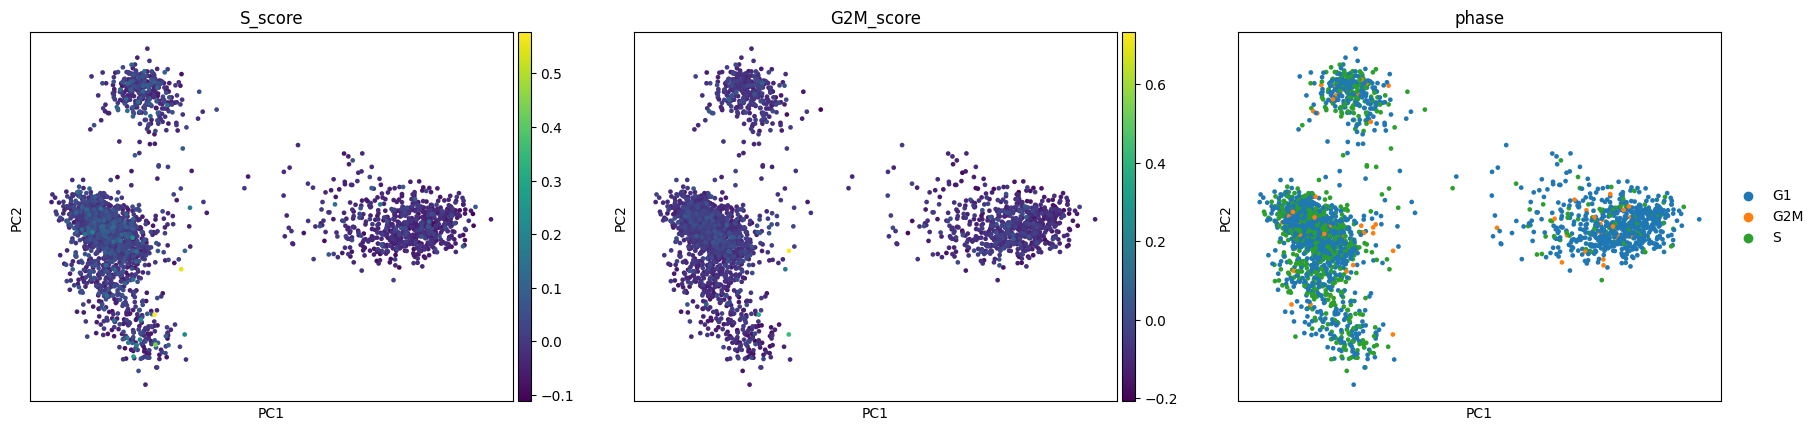

In [72]:
sc.pl.pca(cc, color=["S_score", "G2M_score", "phase"], ncols=3)

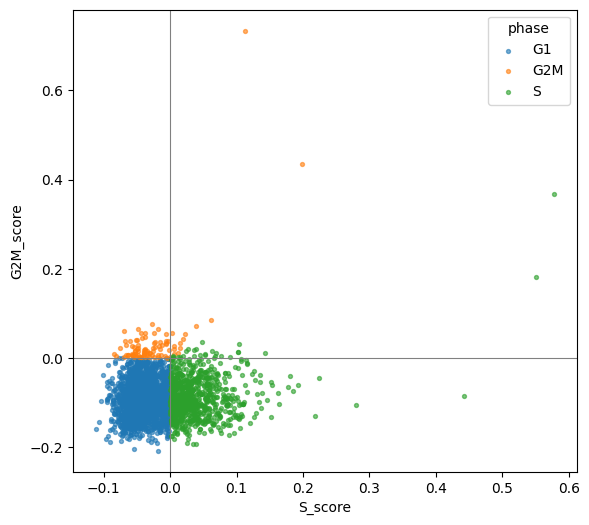

In [73]:
fig, ax = plt.subplots(figsize=(6.5, 6))

for phase, sub in cc.obs.groupby("phase", observed=True):
    ax.scatter(sub.S_score, sub.G2M_score, s=8, alpha=0.6, label=phase)

ax.axhline(0, color="grey", lw=0.8)
ax.axvline(0, color="grey", lw=0.8)
ax.set_xlabel("S_score")
ax.set_ylabel("G2M_score")
ax.legend(title="phase")
plt.show()

In [74]:
cycle_corr = pd.DataFrame({
    f"PC{i+1}": {
        score: round(float(np.corrcoef(cc.obsm["X_pca"][:, i], cc.obs[score])[0, 1]), 2)
        for score in ["S_score", "G2M_score"]
    }
    for i in range(5)
})
cycle_corr

,PC1,PC2,PC3,PC4,PC5
S_score,-0.25,-0.01,0.06,0.01,-0.06
G2M_score,-0.09,0.05,-0.05,0.02,0.01


1. Не разделяются — цвета перемешаны во всех трёх облаках. Счётчик даёт 1713 G1 / 835 S / 90 G2M, но 835 «S» — артефакт: фаза ставится по знаку и максимуму скоров, а всё облако на графики сидит кучей вокруг нуля (±0.1), линии разреза идут ровно по осям. Реально выбиваются единицы точек со скором 0.4–0.7. PBMC — покоящиеся клетки в G0/G1, делящихся в крови почти нет.

2. Нет: `S_score около PC1` = −0.25, `G2M_score около PC1` = −0.09, остальное в пределах ±0.06. И эти −0.25 скорее не цикл — PC1 отрицательным концом смотрит на лимфоидную сторону, где часть S-генов просто выше фоном. Регрессировать цикл здесь не надо, вычитаем шум вместе с сигналом.

3. Скор — не измерение фазы, а среднее по набору генов против случайного контроля; при десятках UMI и дропаутах есть шум, разброс ±0.1. Плюс клетки не синхронизированы — часть лимфоцитов активирована. Плюс часть генов работает вне деления (HMGB2, TUBB4B, CTCF). И нашлось только 37 S-генов из 44 и 44 G2M из 56, так что часть сигнала потеряна.